# 20 GHSL Bhubaneswar Three-Product Production and Historical Evaluation

This notebook reproduces the validated held-out-city workflow for **Bhubaneswar Metropolitan Region**. It first processes all three GHSL products for ten historical epochs, then applies the frozen six-city models without retraining and compares predicted versus actual values for nine five-year transitions.

## Study window

- Seed: 85.824539° E, 20.296059° N
- Projection: ESRI:54009 (World Mollweide)
- Snapped centre: x 6,909,000 m; y 2,817,000 m
- 70 km × 70 km extent: x 6,874,000–6,944,000 m; y 2,782,000–2,852,000 m
- Grid: 70 × 70 = 4,900 one-kilometre cells per epoch
- Actual epochs: 1975–2020 at five-year intervals

## Predictions

The notebook uses the frozen six-city models for built surface, population, and Degree of Urbanisation. Bhubaneswar is not added to training or model selection. Each transition uses the actual source epoch, not an earlier predicted epoch. Thus ten observed epochs produce nine prediction comparisons from 1975→1980 through 2015→2020.

## Execution rule

Run cells in order. The production launch is detached. After launching, rerun the monitor until `COMPLETION_RESULT=SUCCESS`; only then continue to the production audit, longitudinal build, and three-product evaluation.

This notebook is a controlled city-parameter conversion of the validated source notebook. Production, evaluation, exports, metrics, and graphs are unchanged; only Bhubaneswar identity, bounds, paths, and its verified 12-tile population expectation differ.


In [1]:
# ============================================================
# CELL 1: BOOTSTRAP
# ============================================================
from google.colab import drive
from pathlib import Path
import base64, csv, hashlib, json, os, shutil, subprocess, textwrap, time

drive.mount('/content/drive',force_remount=False)
D=Path('/content/drive/MyDrive');REMOTE_EXEC=D/'remote_exec.sh';DRIVE_KEY=D/'hadoop-hdfs.pem';LOCAL_KEY=Path('/content/hadoop-hdfs.pem')
ARTIFACT_ROOT=D/'GHSL_Urban_Growth_Model'/'bhubaneswar_unseen_city_evaluation_v1'
TRAINING_MANIFEST=D/'GHSL_Urban_Growth_Model'/'model_training_v1'/'training_manifest.json'
for p in [REMOTE_EXEC,DRIVE_KEY,TRAINING_MANIFEST]:
    if not p.is_file():raise FileNotFoundError(str(p))
REMOTE_EXEC.chmod(0o700)
if LOCAL_KEY.exists():LOCAL_KEY.unlink()
shutil.copy2(DRIVE_KEY,LOCAL_KEY);LOCAL_KEY.chmod(0o600)
ARTIFACT_ROOT.mkdir(parents=True,exist_ok=True)
def run_remote(command,timeout=300,show_output=True,raise_on_error=True):
    r=subprocess.run(['bash',str(REMOTE_EXEC),command],text=True,capture_output=True,timeout=timeout)
    if show_output and r.stdout:print(r.stdout)
    if show_output and r.stderr:print('REMOTE STDERR:');print(r.stderr)
    if raise_on_error and r.returncode:raise RuntimeError('Remote command failed with return code '+str(r.returncode))
    return r
print('CELL 1: SUCCESS')

Mounted at /content/drive
CELL 1: SUCCESS


In [2]:
# ============================================================
# CELL 2: FROZEN BHUBANESWAR CONFIGURATION
# ============================================================
ACTIVE_CITY_SLUG='bhubaneswar'
ACTIVE_CITY={
 'city_name':'Bhubaneswar Metropolitan Region','city_slug':'bhubaneswar','seed_lon':85.824539,'seed_lat':20.296059,
 'target_crs':'ESRI:54009','expected_grid_cells':4900,'expected_complete_cells':4900,'expected_partial_cells':0,
 'extent_mollweide':{'min_x':8233000.0,'min_y':2454000.0,'max_x':8303000.0,'max_y':2524000.0},
 'hdfs_output_base':'hdfs://localhost:9000/data/ghsl/curated/cities/city=bhubaneswar',
 'remote_work_dir':'/home/ubuntu/ghsl_multicity/bhubaneswar'
}
assert ACTIVE_CITY['extent_mollweide']['max_x']-ACTIVE_CITY['extent_mollweide']['min_x']==70000
assert ACTIVE_CITY['extent_mollweide']['max_y']-ACTIVE_CITY['extent_mollweide']['min_y']==70000
EXPECTED_EPOCHS=[1975,1980,1985,1990,1995,2000,2005,2010,2015,2020]
BHUBANESWAR_HDFS_ROOT=ACTIVE_CITY['hdfs_output_base']
BHUBANESWAR_LONG='/data/ghsl/modeling/bhubaneswar_longitudinal_v1'
BHUBANESWAR_TRANS='/data/ghsl/modeling/bhubaneswar_transitions_v1'
BHUBANESWAR_EVAL='/data/ghsl/modeling/evaluation/bhubaneswar_unseen_city_v1'
EVAL_MODEL='/data/ghsl/modeling/models/six_city_growth_v1/linear_regression'
print(json.dumps(ACTIVE_CITY,indent=2));print('CELL 2: SUCCESS')

{
  "city_name": "Bhubaneswar Metropolitan Region",
  "city_slug": "bhubaneswar",
  "seed_lon": 85.824539,
  "seed_lat": 20.296059,
  "target_crs": "ESRI:54009",
  "expected_grid_cells": 4900,
  "expected_complete_cells": 4900,
  "expected_partial_cells": 0,
  "extent_mollweide": {
    "min_x": 8233000.0,
    "min_y": 2454000.0,
    "max_x": 8303000.0,
    "max_y": 2524000.0
  },
  "hdfs_output_base": "hdfs://localhost:9000/data/ghsl/curated/cities/city=bhubaneswar",
  "remote_work_dir": "/home/ubuntu/ghsl_multicity/bhubaneswar"
}
CELL 2: SUCCESS


In [3]:
# ============================================================
# CELL 3: FROZEN BASELINE AND HDFS PREFLIGHT
# ============================================================
cmd=r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop;export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"
BASE=/home/ubuntu/ghsl_multicity_baseline
for d in NameNode DataNode SecondaryNameNode;do jps|awk '{print $2}'|grep -qx "$d";done
hdfs dfsadmin -safemode get|grep -qi 'Safe mode is OFF'
for f in baseline_manifest.json SHA256SUMS README.txt source_city_config.json batch/run_city_epochs.py templates/population_epoch_template.py templates/smod_epoch_template.py templates/built_surface_epoch_template.py;do test -f "$BASE/$f";done
cd "$BASE";sha256sum -c SHA256SUMS
if hdfs dfs -test -e /data/ghsl/curated/cities/city=bhubaneswar;then echo 'ERROR: Bhubaneswar HDFS root already exists. Audit it before rebuilding.';exit 30;fi
echo BHUBANESWAR_BASELINE_PREFLIGHT_SUCCESS
"""
r=run_remote(cmd,300)
print('CELL 3: SUCCESS')

baseline_manifest.json: OK
batch/run_city_epochs.py: OK
source_city_config.json: OK
templates/built_surface_epoch_template.py: OK
templates/population_epoch_template.py: OK
templates/smod_epoch_template.py: OK
BHUBANESWAR_BASELINE_PREFLIGHT_SUCCESS

REMOTE STDERR:

CELL 3: SUCCESS


In [4]:
# ============================================================
# CELL 4: CREATE BHUBANESWAR WORKSPACE FROM FROZEN BASELINE
# Refuses an incomplete or existing workspace.
# ============================================================
config_b64=base64.b64encode((json.dumps(ACTIVE_CITY,indent=2,sort_keys=True)+'\n').encode()).decode()
builder=r"""from pathlib import Path
import ast,hashlib,json,py_compile,shutil,sys,time
BASE=Path('/home/ubuntu/ghsl_multicity_baseline');TARGET=Path('/home/ubuntu/ghsl_multicity/bhubaneswar');CONFIG=Path(sys.argv[1])
def sha(p):
 h=hashlib.sha256();h.update(p.read_bytes());return h.hexdigest()
cfg=json.loads(CONFIG.read_text());src=json.loads((BASE/'source_city_config.json').read_text())
if cfg['city_slug']!='bhubaneswar' or cfg['extent_mollweide']!={'min_x':8233000.0,'min_y':2454000.0,'max_x':8303000.0,'max_y':2524000.0}:raise RuntimeError('Bhubaneswar config mismatch')
manifest=TARGET/'bhubaneswar_workspace_manifest.json'
if TARGET.exists():
 shutil.rmtree(TARGET)
 print('REMOVED_EXISTING_BHUBANESWAR_WORKSPACE')
source_extent=src['extent_mollweide'];target_extent=cfg['extent_mollweide']
repl=[(src['remote_work_dir'],cfg['remote_work_dir']),('city='+src['city_slug'],'city=bhubaneswar'),(src['city_slug'],'bhubaneswar'),(src['city_name'],cfg['city_name'])]
for k in ['min_x','min_y','max_x','max_y']:
 repl += [(str(float(source_extent[k])),str(float(target_extent[k]))),(str(int(source_extent[k])),str(int(target_extent[k])))]
def param(x):
 for a,b in repl:x=x.replace(a,b)
 return x
try:
 for d in ['templates','programs','batch']:(TARGET/d).mkdir(parents=True,exist_ok=False)
 hashes={}
 for n in ['population_epoch_template.py','smod_epoch_template.py','built_surface_epoch_template.py']:
  dst=TARGET/'templates'/n;txt=param((BASE/'templates'/n).read_text());compile(txt,str(dst),'exec');dst.write_text(txt);py_compile.compile(str(dst),doraise=True);hashes[n]=sha(dst)
 driver=TARGET/'batch'/'run_city_epochs.py';txt=param((BASE/'batch'/'run_city_epochs.py').read_text());tree=ast.parse(txt)
 node=next((n for n in tree.body if isinstance(n,ast.Assign) and any(isinstance(t,ast.Name) and t.id=='EXPECTED_TEMPLATE_SHA256' for t in n.targets)),None)
 if node is None:raise RuntimeError('Checksum dictionary missing')
 dct={'population':hashes['population_epoch_template.py'],'smod':hashes['smod_epoch_template.py'],'built_surface':hashes['built_surface_epoch_template.py']}
 lines=txt.splitlines(keepends=True);lines[node.lineno-1:node.end_lineno]=['EXPECTED_TEMPLATE_SHA256 = '+repr(dct)+'\n'];txt=''.join(lines)
 compile(txt,str(driver),'exec');driver.write_text(txt);py_compile.compile(str(driver),doraise=True)
 (TARGET/'city_config.json').write_text(json.dumps(cfg,indent=2,sort_keys=True)+'\n')
 combined=txt+''.join((TARGET/'templates'/n).read_text() for n in hashes)
 for forbidden in [src['remote_work_dir'],'city='+src['city_slug'],src['city_name']]:
  if forbidden in combined:raise RuntimeError('Source-city leakage: '+forbidden)
 for required in ['/home/ubuntu/ghsl_multicity/bhubaneswar','city=bhubaneswar','8233000','2454000','8303000','2524000']:
  if required not in combined:raise RuntimeError('Missing Bhubaneswar parameter: '+required)
 for p in TARGET.rglob('__pycache__'):shutil.rmtree(p)
 manifest.write_text(json.dumps({'city_slug':'bhubaneswar','city_name':cfg['city_name'],'workspace':str(TARGET),'driver_sha256':sha(driver),'template_sha256':dct,'extent_mollweide':target_extent,'expected_grid_cells':4900,'created_at_utc':time.strftime('%Y-%m-%dT%H:%M:%SZ',time.gmtime())},indent=2,sort_keys=True)+'\n')
except Exception:
 if TARGET.exists():shutil.rmtree(TARGET)
 raise
print('BHUBANESWAR_WORKSPACE_BUILD_SUCCESS')
"""
compile(builder,'builder.py','exec');builder_b64=base64.b64encode(builder.encode()).decode()
cmd=f"""set -e
B=/tmp/build_bhubaneswar_workspace.py;C=/tmp/bhubaneswar_city_config.json
echo '{builder_b64}'|base64 -d > "$B";echo '{config_b64}'|base64 -d > "$C";python3 -m py_compile "$B";python3 "$B" "$C";rm -f "$B" "$C"
"""
r=run_remote(cmd,300)
print('CELL 4: SUCCESS')

REMOVED_EXISTING_BHUBANESWAR_WORKSPACE
BHUBANESWAR_WORKSPACE_BUILD_SUCCESS

REMOTE STDERR:

CELL 4: SUCCESS


In [5]:
# ============================================================
# CELL 5: BHUBANESWAR WORKSPACE FINALIZATION
# Runs once after clean workspace creation and before all audits.
# Preserves the validated source workflow and changes only city-specific values.
# ============================================================
root=ACTIVE_CITY['remote_work_dir']
cmd=r"""set -e
ROOT='__ROOT__'
python3 - "$ROOT" <<'PY_REMOTE'
from pathlib import Path
import ast, hashlib, json, py_compile, re, shutil, sys
root=Path(sys.argv[1]);driver=root/'batch'/'run_city_epochs.py'
templates={'population':root/'templates'/'population_epoch_template.py','smod':root/'templates'/'smod_epoch_template.py','built_surface':root/'templates'/'built_surface_epoch_template.py'}
def sha(p):
 h=hashlib.sha256();h.update(p.read_bytes());return h.hexdigest()

def patch_population(text):
 # Baseline templates retain a legacy Bengaluru Spark application label.
 text=text.replace('"GHSL-Bengaluru-2020-"','"GHSL-Bhubaneswar-2020-"')
 text=text.replace('BATCH: BENGALURU','BATCH: BHUBANESWAR').replace('Bengaluru source shards','Bhubaneswar source shards')
 # Preserve formatting and change the actual constant, not only the error message.
 pat=re.compile(r'(?m)^(?P<prefix>[ \t]*EXPECTED_SELECTED_TILES(?:[ \t]*:[ \t]*[^=\n]+)?[ \t]*=[ \t]*)(?P<value>\d+)(?P<suffix>[ \t]*(?:#.*)?)$')
 matches=list(pat.finditer(text))
 if len(matches)!=1: raise RuntimeError('Expected one EXPECTED_SELECTED_TILES assignment, found '+str(len(matches)))
 text=pat.sub(lambda m:m.group('prefix')+'12'+m.group('suffix'),text,count=1)
 text,n=re.subn(r'Expected\s+\d+\s+selected\s+tiles','Expected 12 selected tiles',text,count=1)
 if n!=1: raise RuntimeError('Expected one selected-tile error message, found '+str(n))
 return text

# Only population has the selected-source-tile guard. SMOD and built remain structurally unchanged.
pop=templates['population'];text=patch_population(pop.read_text());compile(text,str(pop),'exec');pop.write_text(text);py_compile.compile(str(pop),doraise=True)
for stage in ['smod','built_surface']:
 py_compile.compile(str(templates[stage]),doraise=True)

# Semantic checks against the exact real template.
tree=ast.parse(pop.read_text());tile=[];guards=[];apps=[]
for node in ast.walk(tree):
 if isinstance(node,(ast.Assign,ast.AnnAssign)):
  names=[]
  if isinstance(node,ast.Assign): names=[t.id for t in node.targets if isinstance(t,ast.Name)]
  elif isinstance(node.target,ast.Name): names=[node.target.id]
  if 'EXPECTED_SELECTED_TILES' in names:
   if not isinstance(node.value,ast.Constant): raise RuntimeError('Tile expectation is not constant')
   tile.append(node.value.value)
 if isinstance(node,ast.If):
  raises=' '.join(ast.unparse(x) for x in ast.walk(node) if isinstance(x,ast.Raise)).lower()
  if 'selected tile' in raises: guards.append(ast.unparse(node.test))
 if isinstance(node,ast.Constant) and isinstance(node.value,str) and node.value.startswith('GHSL-'): apps.append(node.value)
if tile!=[12]: raise RuntimeError('Tile expectation is not [12]: '+repr(tile))
if guards!=['selected_tile_count != EXPECTED_SELECTED_TILES']: raise RuntimeError('Unexpected tile guard: '+repr(guards))
if apps!=['GHSL-Bhubaneswar-2020-Population-100m-to-1km']: raise RuntimeError('Unexpected population app name: '+repr(apps))
required=['    "epoch=2020/"','EPOCH = 2020','"GHSL-Bhubaneswar-2020-"','"population_2020_catalog"','FROM population_2020_catalog','city=bhubaneswar']
for marker in required:
 if pop.read_text().count(marker)!=1: raise RuntimeError('Population factory marker count failed: '+repr(marker))

# Refresh protected checksums in the real driver.
hashes={stage:sha(path) for stage,path in templates.items()}
source=driver.read_text();tree=ast.parse(source);node=next((n for n in tree.body if isinstance(n,ast.Assign) and any(isinstance(t,ast.Name) and t.id=='EXPECTED_TEMPLATE_SHA256' for t in n.targets)),None)
if node is None:raise RuntimeError('EXPECTED_TEMPLATE_SHA256 missing')
lines=source.splitlines(keepends=True);lines[node.lineno-1:node.end_lineno]=['EXPECTED_TEMPLATE_SHA256 = '+repr(hashes)+'\n'];source=''.join(lines);compile(source,str(driver),'exec');driver.write_text(source);py_compile.compile(str(driver),doraise=True)
manifest=root/'bhubaneswar_workspace_manifest.json'
m=json.loads(manifest.read_text());m['selected_source_tile_expectation']=12;m['driver_sha256']=sha(driver);m['template_sha256']=hashes;m['population_application_name']='GHSL-Bhubaneswar-2020-Population-100m-to-1km';manifest.write_text(json.dumps(m,indent=2,sort_keys=True)+'\n')
for p in root.rglob('__pycache__'):shutil.rmtree(p)
print(json.dumps({'expected_selected_tiles':12,'population_application_name':apps[0],'template_sha256':hashes},indent=2,sort_keys=True))
print('BHUBANESWAR_WORKSPACE_FINALIZATION_SUCCESS')
PY_REMOTE
python3 -m py_compile "$ROOT/batch/run_city_epochs.py" "$ROOT"/templates/*.py
echo BHUBANESWAR_WORKSPACE_FINALIZATION_REMOTE_SUCCESS
""".replace('__ROOT__',root)
r=run_remote(cmd,600)
for marker in ['BHUBANESWAR_WORKSPACE_FINALIZATION_SUCCESS','BHUBANESWAR_WORKSPACE_FINALIZATION_REMOTE_SUCCESS']:
    if marker not in r.stdout:raise RuntimeError('Missing marker: '+marker)
print('Expected population source tiles: 12')
print('Frozen baseline modified: NO')
print('HDFS modified: NO')
print('CELL 5: SUCCESS')

{
  "expected_selected_tiles": 12,
  "population_application_name": "GHSL-Bhubaneswar-2020-Population-100m-to-1km",
  "template_sha256": {
    "built_surface": "cefcbebde469b151dbee63542fd6e17a74fbee561cae5d6bb5c6db40e436d475",
    "population": "d2f22f51ac43c85aba94cbc17fea443f4764da08abaec6fbd484b31edcb62ad4",
    "smod": "a9a69a90f41428d1a103afaf096a2876c1709bf9f70acbc93cc1ba664118ffb3"
  }
}
BHUBANESWAR_WORKSPACE_FINALIZATION_SUCCESS
BHUBANESWAR_WORKSPACE_FINALIZATION_REMOTE_SUCCESS

REMOTE STDERR:

Expected population source tiles: 12
Frozen baseline modified: NO
HDFS modified: NO
CELL 5: SUCCESS


In [6]:
# ============================================================
# CELL 5: STATIC BHUBANESWAR WORKSPACE AUDIT
# ============================================================
root=ACTIVE_CITY['remote_work_dir']
cmd=f"""set -e
ROOT='{root}';DRIVER="$ROOT/batch/run_city_epochs.py"
for f in "$DRIVER" "$ROOT/city_config.json" "$ROOT/bhubaneswar_workspace_manifest.json" "$ROOT/templates/population_epoch_template.py" "$ROOT/templates/smod_epoch_template.py" "$ROOT/templates/built_surface_epoch_template.py";do test -f "$f";done
PYTHONPYCACHEPREFIX=/tmp/bhubaneswar_compile python3 -m py_compile "$DRIVER" "$ROOT"/templates/*.py
python3 - "$ROOT" <<'PY_REMOTE'
from pathlib import Path
import ast,json,sys
r=Path(sys.argv[1]);cfg=json.loads((r/'city_config.json').read_text());src=(r/'batch'/'run_city_epochs.py').read_text()+''.join(p.read_text() for p in (r/'templates').glob('*.py'))
assert cfg['city_slug']=='bhubaneswar' and cfg['expected_grid_cells']==4900 and cfg['target_crs']=='ESRI:54009'
assert cfg['extent_mollweide']=={{'min_x':8233000.0,'min_y':2454000.0,'max_x':8303000.0,'max_y':2524000.0}}
for x in ['city=bhubaneswar','8233000','2454000','8303000','2524000']:assert x in src,x
for x in ['city=pune_metro','city=hyderabad','Pune Metropolitan Region','Hyderabad Metropolitan Region']:assert x not in src,x
print('BHUBANESWAR_STRUCTURAL_AUDIT_SUCCESS')
PY_REMOTE
test ! -e "$ROOT/batch/city.pid";test ! -e "$ROOT/batch/city.log"
rm -rf /tmp/bhubaneswar_compile
echo BHUBANESWAR_STATIC_AUDIT_SUCCESS
"""
r=run_remote(cmd,300)
print('CELL 5: SUCCESS')

BHUBANESWAR_STRUCTURAL_AUDIT_SUCCESS
BHUBANESWAR_STATIC_AUDIT_SUCCESS

REMOTE STDERR:

CELL 5: SUCCESS


In [8]:
# ============================================================
# FIX BHUBANESWAR DRIVER POPULATION APPLICATION MARKER
#
# Current mismatch:
#   Population template:
#       "GHSL-Bhubaneswar-2020-"
#
#   Batch driver:
#       "GHSL-Bengaluru-2020-"
#
# This cell changes only the Bhubaneswar batch driver,
# refreshes its workspace-manifest checksum, and tests the
# real population factory for all ten epochs.
#
# HDFS and frozen baseline are not modified.
# ============================================================

from pathlib import Path

import json


for required_name in [
    "ACTIVE_CITY",
    "ACTIVE_CITY_SLUG",
    "run_remote",
]:
    if required_name not in globals():
        raise RuntimeError(
            required_name
            + " is unavailable. Run Cells 1-5 first."
        )


if ACTIVE_CITY_SLUG != "bhubaneswar":
    raise RuntimeError(
        "Expected ACTIVE_CITY_SLUG='bhubaneswar', found "
        + repr(
            ACTIVE_CITY_SLUG
        )
    )


BHUBANESWAR_WORKSPACE = ACTIVE_CITY[
    "remote_work_dir"
]


repair_command = r'''
set -e

ROOT="__WORKSPACE__"

DRIVER="$ROOT/batch/run_city_epochs.py"
POPULATION_TEMPLATE="$ROOT/templates/population_epoch_template.py"
MANIFEST="$ROOT/bhubaneswar_workspace_manifest.json"

PID_FILE="$ROOT/batch/city.pid"
LOG_FILE="$ROOT/batch/city.log"
BATCH_MANIFEST="$ROOT/batch/batch_manifest.tsv"


echo "============================================================"
echo "BHUBANESWAR DRIVER MARKER REPAIR"
echo "============================================================"


for required_file in \
    "$DRIVER" \
    "$POPULATION_TEMPLATE" \
    "$MANIFEST"
do
    if [ ! -f "$required_file" ]; then
        echo "ERROR: Missing required file:"
        echo "$required_file"
        exit 20
    fi
done


if [ -f "$PID_FILE" ]; then
    RECORDED_PID="$(cat "$PID_FILE")"

    if kill -0 "$RECORDED_PID" 2>/dev/null; then
        echo "ERROR: Bhubaneswar production is running."
        exit 21
    fi
fi


python3 - \
    "$ROOT" \
    <<'PY_REMOTE'
from pathlib import Path

import ast
import hashlib
import json
import py_compile
import shutil
import sys
import tempfile


root = Path(
    sys.argv[1]
)

driver_path = (
    root
    / "batch"
    / "run_city_epochs.py"
)

population_template_path = (
    root
    / "templates"
    / "population_epoch_template.py"
)

manifest_path = (
    root
    / "bhubaneswar_workspace_manifest.json"
)


def sha256_file(
    path,
):
    digest = hashlib.sha256()

    with path.open(
        "rb"
    ) as handle:
        for block in iter(
            lambda: handle.read(
                1024 * 1024
            ),
            b"",
        ):
            digest.update(
                block
            )

    return digest.hexdigest()


# ============================================================
# VERIFY THE TEMPLATE IS ALREADY CORRECT
# ============================================================

population_template = (
    population_template_path
    .read_text(
        encoding="utf-8"
    )
)


template_marker = (
    '"GHSL-Bhubaneswar-2020-"'
)


if population_template.count(
    template_marker
) != 1:
    raise RuntimeError(
        "Expected exactly one Bhubaneswar application marker "
        "in the population template, found "
        + str(
            population_template.count(
                template_marker
            )
        )
    )


if (
    '"GHSL-Bengaluru-2020-"'
    in population_template
):
    raise RuntimeError(
        "The population template still contains "
        "the Bengaluru application marker."
    )


# ============================================================
# PATCH ONLY THE DRIVER FACTORY MARKER
# ============================================================

driver_source = driver_path.read_text(
    encoding="utf-8"
)


old_driver_marker = (
    '\'"GHSL-Bengaluru-2020-"\''
)

new_driver_marker = (
    '\'"GHSL-Bhubaneswar-2020-"\''
)


old_count = driver_source.count(
    old_driver_marker
)

new_count = driver_source.count(
    new_driver_marker
)


if (
    old_count == 1
    and new_count == 0
):
    driver_source = driver_source.replace(
        old_driver_marker,
        new_driver_marker,
        1,
    )

    changed = True

elif (
    old_count == 0
    and new_count == 1
):
    # Safe if the cell is rerun.
    changed = False

else:
    raise RuntimeError(
        "Unexpected driver marker inventory: "
        + repr(
            {
                "Bengaluru_marker_count": (
                    old_count
                ),
                "Bhubaneswar_marker_count": (
                    new_count
                ),
            }
        )
    )


compile(
    driver_source,
    str(
        driver_path
    ),
    "exec",
)


driver_path.write_text(
    driver_source,
    encoding="utf-8",
)


py_compile.compile(
    str(
        driver_path
    ),
    doraise=True,
)


# ============================================================
# VERIFY EXACT FACTORY MARKER
# ============================================================

saved_driver_source = driver_path.read_text(
    encoding="utf-8"
)


if saved_driver_source.count(
    new_driver_marker
) != 1:
    raise RuntimeError(
        "The saved driver does not contain exactly one "
        "Bhubaneswar population application marker."
    )


if old_driver_marker in saved_driver_source:
    raise RuntimeError(
        "The saved driver still contains the Bengaluru marker."
    )


# ============================================================
# TEST THE REAL POPULATION FACTORY FOR ALL TEN EPOCHS
# ============================================================

driver_tree = ast.parse(
    saved_driver_source
)


allowed_nodes = (
    ast.Import,
    ast.ImportFrom,
    ast.Assign,
    ast.AnnAssign,
    ast.FunctionDef,
    ast.AsyncFunctionDef,
    ast.ClassDef,
)


definition_module = ast.Module(
    body=[
        node
        for node
        in driver_tree.body
        if isinstance(
            node,
            allowed_nodes,
        )
    ],
    type_ignores=[],
)


ast.fix_missing_locations(
    definition_module
)


namespace = {
    "__file__": str(
        driver_path
    ),
    "__name__": (
        "bhubaneswar_driver_marker_test"
    ),
}


exec(
    compile(
        definition_module,
        str(
            driver_path
        ),
        "exec",
    ),
    namespace,
)


population_factory = namespace[
    "generate_population_program"
]


epochs = [
    1975,
    1980,
    1985,
    1990,
    1995,
    2000,
    2005,
    2010,
    2015,
    2020,
]


temporary_root = Path(
    tempfile.mkdtemp(
        prefix=(
            "bhubaneswar_population_factory_"
        )
    )
)


try:
    for epoch in epochs:
        epoch_directory = (
            temporary_root
            / str(
                epoch
            )
        )

        epoch_directory.mkdir()


        program_path = Path(
            population_factory(
                epoch,
                epoch_directory,
            )
        )


        py_compile.compile(
            str(
                program_path
            ),
            doraise=True,
        )


        program_source = (
            program_path
            .read_text(
                encoding="utf-8"
            )
        )


        expected_application_name = (
            "GHSL-Bhubaneswar-"
            + str(
                epoch
            )
            + "-Population-100m-to-1km"
        )


        if (
            program_source.count(
                expected_application_name
            )
            != 1
        ):
            raise RuntimeError(
                "Generated program does not contain "
                + expected_application_name
                + ": "
                + str(
                    program_path
                )
            )


        if (
            "GHSL-Bengaluru-"
            in program_source
        ):
            raise RuntimeError(
                "Generated program retains Bengaluru marker: "
                + str(
                    program_path
                )
            )


        if (
            "city=bhubaneswar"
            not in program_source
        ):
            raise RuntimeError(
                "Generated program lacks Bhubaneswar HDFS path: "
                + str(
                    program_path
                )
            )


        print(
            "PASS:",
            epoch,
            program_path.name,
            expected_application_name,
        )


finally:
    shutil.rmtree(
        temporary_root
    )


# ============================================================
# REFRESH MANIFEST DRIVER CHECKSUM
# ============================================================

manifest = json.loads(
    manifest_path.read_text(
        encoding="utf-8"
    )
)


manifest[
    "driver_sha256"
] = sha256_file(
    driver_path
)

manifest[
    "population_driver_application_marker"
] = (
    "GHSL-Bhubaneswar-2020-"
)


manifest_path.write_text(
    json.dumps(
        manifest,
        indent=2,
        sort_keys=True,
    )
    + "\n",
    encoding="utf-8",
)


print(
    json.dumps(
        {
            "driver_changed": (
                changed
            ),
            "driver_sha256": (
                sha256_file(
                    driver_path
                )
            ),
            "population_factory_epochs_verified": (
                epochs
            ),
        },
        indent=2,
        sort_keys=True,
    )
)


print(
    "ALL_10_BHUBANESWAR_POPULATION_FACTORIES_PASS"
)

print(
    "BHUBANESWAR_DRIVER_MARKER_PATCH_SUCCESS"
)
PY_REMOTE


rm -f \
    "$PID_FILE" \
    "$LOG_FILE" \
    "$BATCH_MANIFEST"


echo
echo "Failed launch state removed: PASS"
echo "Frozen baseline modified: NO"
echo "HDFS modified: NO"
echo "BHUBANESWAR_DRIVER_MARKER_REPAIR_SUCCESS"
'''


repair_command = repair_command.replace(
    "__WORKSPACE__",
    BHUBANESWAR_WORKSPACE,
)


repair_result = run_remote(
    repair_command,
    timeout=600,
    show_output=True,
)


for marker in [
    "ALL_10_BHUBANESWAR_POPULATION_FACTORIES_PASS",
    "BHUBANESWAR_DRIVER_MARKER_PATCH_SUCCESS",
    "BHUBANESWAR_DRIVER_MARKER_REPAIR_SUCCESS",
]:
    if marker not in repair_result.stdout:
        raise RuntimeError(
            "Missing repair marker: "
            + marker
        )


print(
    "Bhubaneswar population factories: 10/10 PASS"
)

print(
    "Frozen baseline modified: NO"
)

print(
    "HDFS modified: NO"
)

print(
    "BHUBANESWAR DRIVER MARKER REPAIR: SUCCESS"
)

BHUBANESWAR DRIVER MARKER REPAIR

REMOTE STDERR:
Traceback (most recent call last):
  File "<stdin>", line 143, in <module>
RuntimeError: Unexpected driver marker inventory: {'Bengaluru_marker_count': 2, 'Bhubaneswar_marker_count': 0}



RuntimeError: Remote command failed with return code 1

In [9]:
# ============================================================
# BHUBANESWAR UNIFIED APPLICATION-NAME REPAIR
#
# Root cause:
#   The frozen baseline retained legacy Spark application names
#   beginning with:
#
#       GHSL-Bengaluru-2020-
#
#   The Bhubaneswar driver and templates became inconsistent
#   because only some occurrences were converted.
#
# This cell:
#   1. Converts every legacy Spark application prefix in the
#      Bhubaneswar driver and all three Bhubaneswar templates
#   2. Preserves all other source formatting
#   3. Verifies population EXPECTED_SELECTED_TILES = 12
#   4. Refreshes protected template checksums
#   5. Removes failed launch/generated state
#   6. Runs all 30 real driver factories
#   7. Compiles and inspects every generated program
#
# Does not modify HDFS or the frozen baseline.
# ============================================================

for required_name in [
    "ACTIVE_CITY",
    "ACTIVE_CITY_SLUG",
    "run_remote",
]:
    if required_name not in globals():
        raise RuntimeError(
            required_name
            + " is unavailable. Run Cells 1-5 first."
        )


if ACTIVE_CITY_SLUG != "bhubaneswar":
    raise RuntimeError(
        "Expected ACTIVE_CITY_SLUG='bhubaneswar', found "
        + repr(ACTIVE_CITY_SLUG)
    )


BHUBANESWAR_WORKSPACE = ACTIVE_CITY[
    "remote_work_dir"
]


repair_command = r'''
set -e

source /home/ubuntu/ghsl-sedona-env.sh

export HADOOP_HOME=/usr/local/hadoop
export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"

ROOT="__WORKSPACE__"

DRIVER="$ROOT/batch/run_city_epochs.py"
CONFIG="$ROOT/city_config.json"
MANIFEST="$ROOT/bhubaneswar_workspace_manifest.json"

POPULATION_TEMPLATE="$ROOT/templates/population_epoch_template.py"
SMOD_TEMPLATE="$ROOT/templates/smod_epoch_template.py"
BUILT_TEMPLATE="$ROOT/templates/built_surface_epoch_template.py"

PID_FILE="$ROOT/batch/city.pid"
LOG_FILE="$ROOT/batch/city.log"
BATCH_MANIFEST="$ROOT/batch/batch_manifest.tsv"

HDFS_ROOT="/data/ghsl/curated/cities/city=bhubaneswar"


echo "============================================================"
echo "BHUBANESWAR UNIFIED APPLICATION-NAME REPAIR"
echo "============================================================"


# ============================================================
# SAFETY CHECKS
# ============================================================

for required_file in \
    "$DRIVER" \
    "$CONFIG" \
    "$MANIFEST" \
    "$POPULATION_TEMPLATE" \
    "$SMOD_TEMPLATE" \
    "$BUILT_TEMPLATE"
do
    if [ ! -f "$required_file" ]; then
        echo "ERROR: Missing required file:"
        echo "$required_file"
        exit 20
    fi
done


if [ -f "$PID_FILE" ]; then
    RECORDED_PID="$(cat "$PID_FILE")"

    if kill -0 "$RECORDED_PID" 2>/dev/null; then
        echo "ERROR: Bhubaneswar production is still running."
        echo "PID: $RECORDED_PID"
        exit 21
    fi
fi


if hdfs dfs -test -e "$HDFS_ROOT"; then
    echo "ERROR: Bhubaneswar HDFS output already exists:"
    echo "$HDFS_ROOT"
    exit 22
fi


echo "Required files: PASS"
echo "Active Bhubaneswar process: NO"
echo "Existing Bhubaneswar HDFS output: NO"


# ============================================================
# UNIFIED PATCH AND VALIDATION
# ============================================================

python3 - "$ROOT" <<'PY_REMOTE'
from pathlib import Path

import ast
import hashlib
import json
import py_compile
import shutil
import sys
import tempfile
import time


root = Path(sys.argv[1])

driver_path = (
    root
    / "batch"
    / "run_city_epochs.py"
)

config_path = (
    root
    / "city_config.json"
)

manifest_path = (
    root
    / "bhubaneswar_workspace_manifest.json"
)


template_paths = {
    "population": (
        root
        / "templates"
        / "population_epoch_template.py"
    ),
    "smod": (
        root
        / "templates"
        / "smod_epoch_template.py"
    ),
    "built_surface": (
        root
        / "templates"
        / "built_surface_epoch_template.py"
    ),
}


OLD_PREFIX = "GHSL-Bengaluru-2020-"
NEW_PREFIX = "GHSL-Bhubaneswar-2020-"


def sha256_file(path):
    digest = hashlib.sha256()

    with path.open("rb") as handle:
        for block in iter(
            lambda: handle.read(1024 * 1024),
            b"",
        ):
            digest.update(block)

    return digest.hexdigest()


# ============================================================
# VERIFY CITY CONFIGURATION
# ============================================================

config = json.loads(
    config_path.read_text(
        encoding="utf-8"
    )
)


expected_extent = {
    "min_x": 8233000.0,
    "min_y": 2454000.0,
    "max_x": 8303000.0,
    "max_y": 2524000.0,
}


if config.get("city_slug") != "bhubaneswar":
    raise RuntimeError(
        "Unexpected city slug: "
        + repr(config.get("city_slug"))
    )


if config.get("extent_mollweide") != expected_extent:
    raise RuntimeError(
        "Unexpected Bhubaneswar extent: "
        + repr(config.get("extent_mollweide"))
    )


if config.get("expected_grid_cells") != 4900:
    raise RuntimeError(
        "expected_grid_cells must equal 4900."
    )


# ============================================================
# PATCH ALL THREE TEMPLATES
#
# Safe to rerun:
#   - Replace any remaining legacy prefix.
#   - Accept already-correct Bhubaneswar prefixes.
# ============================================================

template_patch_counts = {}


for stage_name, template_path in template_paths.items():
    source = template_path.read_text(
        encoding="utf-8"
    )

    old_count = source.count(
        OLD_PREFIX
    )

    new_count_before = source.count(
        NEW_PREFIX
    )


    source = source.replace(
        OLD_PREFIX,
        NEW_PREFIX,
    )


    if OLD_PREFIX in source:
        raise RuntimeError(
            "Legacy application prefix remains in "
            + str(template_path)
        )


    compile(
        source,
        str(template_path),
        "exec",
    )


    template_path.write_text(
        source,
        encoding="utf-8",
    )


    py_compile.compile(
        str(template_path),
        doraise=True,
    )


    template_patch_counts[
        stage_name
    ] = {
        "legacy_prefixes_replaced": old_count,
        "bhubaneswar_prefixes_before": new_count_before,
        "bhubaneswar_prefixes_after": (
            source.count(NEW_PREFIX)
        ),
    }


# ============================================================
# PATCH EVERY LEGACY DRIVER FACTORY MARKER
#
# The diagnostic showed two driver occurrences.
# Both must be converted, not just one.
# ============================================================

driver_source = driver_path.read_text(
    encoding="utf-8"
)


driver_old_count = driver_source.count(
    OLD_PREFIX
)

driver_new_count_before = driver_source.count(
    NEW_PREFIX
)


driver_source = driver_source.replace(
    OLD_PREFIX,
    NEW_PREFIX,
)


if OLD_PREFIX in driver_source:
    raise RuntimeError(
        "Legacy application prefix remains in the driver."
    )


compile(
    driver_source,
    str(driver_path),
    "exec",
)


driver_path.write_text(
    driver_source,
    encoding="utf-8",
)


py_compile.compile(
    str(driver_path),
    doraise=True,
)


# ============================================================
# VERIFY POPULATION TILE EXPECTATION SEMANTICALLY
# ============================================================

population_source = (
    template_paths[
        "population"
    ]
    .read_text(
        encoding="utf-8"
    )
)

population_tree = ast.parse(
    population_source
)


tile_values = []
tile_guards = []


for node in ast.walk(
    population_tree
):
    names = []

    if isinstance(
        node,
        ast.Assign,
    ):
        names = [
            target.id
            for target
            in node.targets
            if isinstance(
                target,
                ast.Name,
            )
        ]

    elif isinstance(
        node,
        ast.AnnAssign,
    ):
        if isinstance(
            node.target,
            ast.Name,
        ):
            names = [
                node.target.id
            ]


    if "EXPECTED_SELECTED_TILES" in names:
        if not isinstance(
            node.value,
            ast.Constant,
        ):
            raise RuntimeError(
                "EXPECTED_SELECTED_TILES is not constant."
            )

        tile_values.append(
            node.value.value
        )


    if isinstance(
        node,
        ast.If,
    ):
        raise_text = " ".join(
            ast.unparse(descendant)
            for descendant
            in ast.walk(node)
            if isinstance(
                descendant,
                ast.Raise,
            )
        ).lower()


        if "selected tile" in raise_text:
            tile_guards.append(
                ast.unparse(
                    node.test
                )
            )


if tile_values != [12]:
    raise RuntimeError(
        "Population tile expectation must be [12], found "
        + repr(tile_values)
    )


if tile_guards != [
    (
        "selected_tile_count "
        "!= EXPECTED_SELECTED_TILES"
    )
]:
    raise RuntimeError(
        "Unexpected population tile guard: "
        + repr(tile_guards)
    )


# ============================================================
# VERIFY EXACT DRIVER REPLACEMENT CONTRACTS
# ============================================================

saved_driver_source = driver_path.read_text(
    encoding="utf-8"
)


required_driver_markers = [
    '\'"GHSL-Bhubaneswar-2020-"\'',
    '\'"GHSL-Bhubaneswar-2020-SMOD-1km"\'',
]


for marker in required_driver_markers:
    if marker not in saved_driver_source:
        raise RuntimeError(
            "Required Bhubaneswar driver marker is missing: "
            + repr(marker)
        )


# ============================================================
# REFRESH PROTECTED TEMPLATE CHECKSUMS
# ============================================================

template_hashes = {
    stage_name: sha256_file(
        template_path
    )
    for stage_name, template_path
    in template_paths.items()
}


driver_source = driver_path.read_text(
    encoding="utf-8"
)

driver_tree = ast.parse(
    driver_source
)


checksum_node = None


for node in driver_tree.body:
    if not isinstance(
        node,
        ast.Assign,
    ):
        continue

    if any(
        isinstance(
            target,
            ast.Name,
        )
        and target.id
        == "EXPECTED_TEMPLATE_SHA256"
        for target in node.targets
    ):
        checksum_node = node
        break


if checksum_node is None:
    raise RuntimeError(
        "EXPECTED_TEMPLATE_SHA256 is missing."
    )


driver_lines = driver_source.splitlines(
    keepends=True
)


driver_lines[
    checksum_node.lineno - 1:
    checksum_node.end_lineno
] = [
    (
        "EXPECTED_TEMPLATE_SHA256 = "
        + repr(template_hashes)
        + "\n"
    )
]


driver_source = "".join(
    driver_lines
)


compile(
    driver_source,
    str(driver_path),
    "exec",
)


driver_path.write_text(
    driver_source,
    encoding="utf-8",
)


py_compile.compile(
    str(driver_path),
    doraise=True,
)


# ============================================================
# UPDATE WORKSPACE MANIFEST
# ============================================================

manifest = json.loads(
    manifest_path.read_text(
        encoding="utf-8"
    )
)


manifest[
    "driver_sha256"
] = sha256_file(
    driver_path
)

manifest[
    "template_sha256"
] = template_hashes

manifest[
    "selected_source_tile_expectation"
] = 12

manifest[
    "spark_application_prefix"
] = NEW_PREFIX

manifest[
    "unified_application_prefix_repair_at_utc"
] = time.strftime(
    "%Y-%m-%dT%H:%M:%SZ",
    time.gmtime(),
)


manifest_path.write_text(
    json.dumps(
        manifest,
        indent=2,
        sort_keys=True,
    )
    + "\n",
    encoding="utf-8",
)


# ============================================================
# REMOVE FAILED GENERATED STATE
# ============================================================

programs_directory = (
    root
    / "programs"
)


if programs_directory.exists():
    shutil.rmtree(
        programs_directory
    )


programs_directory.mkdir(
    parents=True,
    exist_ok=False,
)


for cache_directory in root.rglob(
    "__pycache__"
):
    shutil.rmtree(
        cache_directory
    )


for bytecode_path in root.rglob(
    "*.pyc"
):
    bytecode_path.unlink()


# ============================================================
# LOAD THE REAL FACTORIES
# ============================================================

saved_driver_source = driver_path.read_text(
    encoding="utf-8"
)

saved_driver_tree = ast.parse(
    saved_driver_source
)


allowed_nodes = (
    ast.Import,
    ast.ImportFrom,
    ast.Assign,
    ast.AnnAssign,
    ast.FunctionDef,
    ast.AsyncFunctionDef,
    ast.ClassDef,
)


definition_module = ast.Module(
    body=[
        node
        for node
        in saved_driver_tree.body
        if isinstance(
            node,
            allowed_nodes,
        )
    ],
    type_ignores=[],
)


ast.fix_missing_locations(
    definition_module
)


namespace = {
    "__file__": str(driver_path),
    "__name__": (
        "bhubaneswar_unified_factory_test"
    ),
}


exec(
    compile(
        definition_module,
        str(driver_path),
        "exec",
    ),
    namespace,
)


factories = {
    "population": (
        namespace[
            "generate_population_program"
        ]
    ),
    "smod": (
        namespace[
            "generate_smod_program"
        ]
    ),
    "built_surface": (
        namespace[
            "generate_built_program"
        ]
    ),
}


epochs = [
    1975,
    1980,
    1985,
    1990,
    1995,
    2000,
    2005,
    2010,
    2015,
    2020,
]


temporary_root = Path(
    tempfile.mkdtemp(
        prefix=(
            "bhubaneswar_unified_factory_"
        )
    )
)


generated_count = 0


try:
    for epoch in epochs:
        epoch_directory = (
            temporary_root
            / f"epoch_{epoch}"
        )

        epoch_directory.mkdir()


        for stage_name, factory in factories.items():
            program_path = Path(
                factory(
                    epoch,
                    epoch_directory,
                )
            )


            if not program_path.is_file():
                raise RuntimeError(
                    "Generated program missing: "
                    + str(program_path)
                )


            py_compile.compile(
                str(program_path),
                doraise=True,
            )


            program_source = (
                program_path.read_text(
                    encoding="utf-8"
                )
            )


            if (
                "city=bhubaneswar"
                not in program_source
            ):
                raise RuntimeError(
                    "Bhubaneswar HDFS identity missing: "
                    + str(program_path)
                )


            if (
                "GHSL-Bengaluru-"
                in program_source
            ):
                raise RuntimeError(
                    "Legacy Bengaluru application name remains: "
                    + str(program_path)
                )


            if (
                "GHSL-Bhubaneswar-"
                + str(epoch)
                not in program_source
            ):
                raise RuntimeError(
                    "Epoch-specific Bhubaneswar application "
                    "name is missing: "
                    + str(program_path)
                )


            if stage_name == "population":
                program_tree = ast.parse(
                    program_source
                )

                generated_tile_values = []


                for node in ast.walk(
                    program_tree
                ):
                    names = []

                    if isinstance(
                        node,
                        ast.Assign,
                    ):
                        names = [
                            target.id
                            for target
                            in node.targets
                            if isinstance(
                                target,
                                ast.Name,
                            )
                        ]

                    elif isinstance(
                        node,
                        ast.AnnAssign,
                    ):
                        if isinstance(
                            node.target,
                            ast.Name,
                        ):
                            names = [
                                node.target.id
                            ]


                    if (
                        "EXPECTED_SELECTED_TILES"
                        in names
                    ):
                        generated_tile_values.append(
                            node.value.value
                        )


                if generated_tile_values != [12]:
                    raise RuntimeError(
                        "Generated population program does "
                        "not use 12 expected tiles: "
                        + repr(generated_tile_values)
                        + " in "
                        + str(program_path)
                    )


            generated_count += 1


            print(
                "PASS:",
                epoch,
                stage_name,
                program_path.name,
            )


    if generated_count != 30:
        raise RuntimeError(
            "Expected 30 generated programs, found "
            + str(generated_count)
        )


finally:
    shutil.rmtree(
        temporary_root
    )


print(
    json.dumps(
        {
            "driver_legacy_prefixes_replaced": (
                driver_old_count
            ),
            "driver_bhubaneswar_prefixes_before": (
                driver_new_count_before
            ),
            "template_patch_counts": (
                template_patch_counts
            ),
            "population_tile_values": (
                tile_values
            ),
            "population_tile_guards": (
                tile_guards
            ),
            "generated_programs_verified": (
                generated_count
            ),
            "driver_sha256": (
                sha256_file(
                    driver_path
                )
            ),
            "template_sha256": (
                template_hashes
            ),
        },
        indent=2,
        sort_keys=True,
    )
)


print(
    "ALL_30_BHUBANESWAR_REAL_FACTORIES_PASS"
)

print(
    "BHUBANESWAR_UNIFIED_APPLICATION_REPAIR_SUCCESS"
)
PY_REMOTE


# ============================================================
# CLEAN FAILED RUN STATE
# ============================================================

rm -f \
    "$PID_FILE" \
    "$LOG_FILE" \
    "$BATCH_MANIFEST"


echo
echo "Failed launch state removed: PASS"
echo "Frozen baseline modified: NO"
echo "HDFS modified: NO"
echo "BHUBANESWAR_UNIFIED_REPAIR_REMOTE_SUCCESS"
'''


repair_command = repair_command.replace(
    "__WORKSPACE__",
    BHUBANESWAR_WORKSPACE,
)


repair_result = run_remote(
    repair_command,
    timeout=900,
    show_output=True,
)


required_markers = [
    "ALL_30_BHUBANESWAR_REAL_FACTORIES_PASS",
    "BHUBANESWAR_UNIFIED_APPLICATION_REPAIR_SUCCESS",
    "BHUBANESWAR_UNIFIED_REPAIR_REMOTE_SUCCESS",
]


missing_markers = [
    marker
    for marker
    in required_markers
    if marker
    not in repair_result.stdout
]


if missing_markers:
    raise RuntimeError(
        "Unified repair is missing markers: "
        + repr(missing_markers)
    )


print(
    "All real driver factories: 30/30 PASS"
)

print(
    "Population expected source tiles: 12 PASS"
)

print(
    "Legacy Bengaluru Spark application names: 0"
)

print(
    "Frozen baseline modified: NO"
)

print(
    "HDFS modified: NO"
)

print(
    "BHUBANESWAR UNIFIED APPLICATION-NAME REPAIR: SUCCESS"
)

BHUBANESWAR UNIFIED APPLICATION-NAME REPAIR
Required files: PASS
Active Bhubaneswar process: NO
Existing Bhubaneswar HDFS output: NO

REMOTE STDERR:
Traceback (most recent call last):
  File "<stdin>", line 695, in <module>
RuntimeError: Legacy Bengaluru application name remains: /tmp/bhubaneswar_unified_factory_5w_caku0/epoch_1975/population_1975.py



RuntimeError: Remote command failed with return code 1

In [10]:
# ============================================================
# BHUBANESWAR WORKSPACE-WIDE SPARK APPLICATION-NAME FIX
#
# Replaces, only inside the Bhubaneswar workspace:
#
#   GHSL-Bengaluru-
#       with
#   GHSL-Bhubaneswar-
#
# Applies to:
#   - Population template
#   - SMOD template
#   - Built-surface template
#   - Batch driver
#
# Then:
#   - Refreshes protected template checksums
#   - Updates workspace manifest
#   - Removes failed generated/run state
#   - Runs all 30 real factories
#   - Verifies no generated program contains GHSL-Bengaluru-
#
# HDFS and frozen baseline are not modified.
# ============================================================

for required_name in [
    "ACTIVE_CITY",
    "ACTIVE_CITY_SLUG",
    "run_remote",
]:
    if required_name not in globals():
        raise RuntimeError(
            required_name
            + " is unavailable. Run Cells 1-5 first."
        )


if ACTIVE_CITY_SLUG != "bhubaneswar":
    raise RuntimeError(
        "Expected bhubaneswar, found "
        + repr(ACTIVE_CITY_SLUG)
    )


workspace = ACTIVE_CITY[
    "remote_work_dir"
]


command = r'''
set -e

source /home/ubuntu/ghsl-sedona-env.sh

export HADOOP_HOME=/usr/local/hadoop
export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"

ROOT="__WORKSPACE__"

DRIVER="$ROOT/batch/run_city_epochs.py"
MANIFEST="$ROOT/bhubaneswar_workspace_manifest.json"

POPULATION_TEMPLATE="$ROOT/templates/population_epoch_template.py"
SMOD_TEMPLATE="$ROOT/templates/smod_epoch_template.py"
BUILT_TEMPLATE="$ROOT/templates/built_surface_epoch_template.py"

PID_FILE="$ROOT/batch/city.pid"
LOG_FILE="$ROOT/batch/city.log"
BATCH_MANIFEST="$ROOT/batch/batch_manifest.tsv"

HDFS_ROOT="/data/ghsl/curated/cities/city=bhubaneswar"


echo "============================================================"
echo "BHUBANESWAR WORKSPACE-WIDE APPLICATION-NAME FIX"
echo "============================================================"


for required_file in \
    "$DRIVER" \
    "$MANIFEST" \
    "$POPULATION_TEMPLATE" \
    "$SMOD_TEMPLATE" \
    "$BUILT_TEMPLATE"
do
    test -f "$required_file"
done


if [ -f "$PID_FILE" ]; then
    RECORDED_PID="$(cat "$PID_FILE")"

    if kill -0 "$RECORDED_PID" 2>/dev/null; then
        echo "ERROR: Production is still running."
        exit 21
    fi
fi


if hdfs dfs -test -e "$HDFS_ROOT"; then
    echo "ERROR: Bhubaneswar HDFS output already exists."
    exit 22
fi


python3 - "$ROOT" <<'PY_REMOTE'
from pathlib import Path

import ast
import hashlib
import json
import py_compile
import shutil
import sys
import tempfile
import time


root = Path(
    sys.argv[1]
)


driver = (
    root
    / "batch"
    / "run_city_epochs.py"
)


templates = {
    "population": (
        root
        / "templates"
        / "population_epoch_template.py"
    ),
    "smod": (
        root
        / "templates"
        / "smod_epoch_template.py"
    ),
    "built_surface": (
        root
        / "templates"
        / "built_surface_epoch_template.py"
    ),
}


manifest_path = (
    root
    / "bhubaneswar_workspace_manifest.json"
)


OLD = "GHSL-Bengaluru-"
NEW = "GHSL-Bhubaneswar-"


def sha256_file(
    path,
):
    digest = hashlib.sha256()

    with path.open(
        "rb"
    ) as handle:
        for block in iter(
            lambda: handle.read(
                1024 * 1024
            ),
            b"",
        ):
            digest.update(
                block
            )

    return digest.hexdigest()


# ============================================================
# REPLACE EVERY LEGACY SPARK APPLICATION CITY PREFIX
# ============================================================

files = [
    driver,
    *templates.values(),
]


replacement_report = {}


for path in files:
    source = path.read_text(
        encoding="utf-8"
    )

    legacy_count = source.count(
        OLD
    )

    source = source.replace(
        OLD,
        NEW,
    )


    if OLD in source:
        raise RuntimeError(
            "Legacy application prefix remains in "
            + str(path)
        )


    compile(
        source,
        str(path),
        "exec",
    )


    path.write_text(
        source,
        encoding="utf-8",
    )


    py_compile.compile(
        str(path),
        doraise=True,
    )


    replacement_report[
        str(path)
    ] = {
        "legacy_prefixes_replaced": (
            legacy_count
        ),
        "bhubaneswar_prefixes_after": (
            source.count(
                NEW
            )
        ),
    }


# ============================================================
# VERIFY POPULATION TILE EXPECTATION
# ============================================================

population_source = (
    templates[
        "population"
    ]
    .read_text(
        encoding="utf-8"
    )
)


population_tree = ast.parse(
    population_source
)


tile_values = []


for node in ast.walk(
    population_tree
):
    names = []

    if isinstance(
        node,
        ast.Assign,
    ):
        names = [
            target.id
            for target
            in node.targets
            if isinstance(
                target,
                ast.Name,
            )
        ]

    elif isinstance(
        node,
        ast.AnnAssign,
    ):
        if isinstance(
            node.target,
            ast.Name,
        ):
            names = [
                node.target.id
            ]


    if (
        "EXPECTED_SELECTED_TILES"
        in names
    ):
        tile_values.append(
            node.value.value
        )


if tile_values != [
    12
]:
    raise RuntimeError(
        "Expected population tile value [12], found "
        + repr(tile_values)
    )


# ============================================================
# REFRESH PROTECTED TEMPLATE CHECKSUMS
# ============================================================

template_hashes = {
    stage: sha256_file(
        path
    )
    for stage, path
    in templates.items()
}


driver_source = driver.read_text(
    encoding="utf-8"
)

driver_tree = ast.parse(
    driver_source
)


checksum_node = next(
    (
        node
        for node
        in driver_tree.body
        if (
            isinstance(
                node,
                ast.Assign,
            )
            and any(
                isinstance(
                    target,
                    ast.Name,
                )
                and target.id
                == "EXPECTED_TEMPLATE_SHA256"
                for target
                in node.targets
            )
        )
    ),
    None,
)


if checksum_node is None:
    raise RuntimeError(
        "EXPECTED_TEMPLATE_SHA256 is missing."
    )


driver_lines = driver_source.splitlines(
    keepends=True
)


driver_lines[
    checksum_node.lineno - 1:
    checksum_node.end_lineno
] = [
    (
        "EXPECTED_TEMPLATE_SHA256 = "
        + repr(
            template_hashes
        )
        + "\n"
    )
]


driver_source = "".join(
    driver_lines
)


compile(
    driver_source,
    str(driver),
    "exec",
)


driver.write_text(
    driver_source,
    encoding="utf-8",
)


py_compile.compile(
    str(driver),
    doraise=True,
)


# ============================================================
# UPDATE MANIFEST
# ============================================================

manifest = json.loads(
    manifest_path.read_text(
        encoding="utf-8"
    )
)


manifest[
    "driver_sha256"
] = sha256_file(
    driver
)

manifest[
    "template_sha256"
] = template_hashes

manifest[
    "spark_application_city_prefix"
] = NEW

manifest[
    "workspace_wide_application_fix_at_utc"
] = time.strftime(
    "%Y-%m-%dT%H:%M:%SZ",
    time.gmtime(),
)


manifest_path.write_text(
    json.dumps(
        manifest,
        indent=2,
        sort_keys=True,
    )
    + "\n",
    encoding="utf-8",
)


# ============================================================
# REMOVE FAILED GENERATED STATE
# ============================================================

programs = (
    root
    / "programs"
)


if programs.exists():
    shutil.rmtree(
        programs
    )


programs.mkdir(
    parents=True,
    exist_ok=False,
)


for cache in root.rglob(
    "__pycache__"
):
    shutil.rmtree(
        cache
    )


# ============================================================
# LOAD ACTUAL DRIVER FACTORIES
# ============================================================

tree = ast.parse(
    driver.read_text(
        encoding="utf-8"
    )
)


allowed = (
    ast.Import,
    ast.ImportFrom,
    ast.Assign,
    ast.AnnAssign,
    ast.FunctionDef,
    ast.AsyncFunctionDef,
    ast.ClassDef,
)


module = ast.Module(
    body=[
        node
        for node
        in tree.body
        if isinstance(
            node,
            allowed,
        )
    ],
    type_ignores=[],
)


ast.fix_missing_locations(
    module
)


namespace = {
    "__file__": str(
        driver
    ),
    "__name__": (
        "bhubaneswar_factory_validation"
    ),
}


exec(
    compile(
        module,
        str(driver),
        "exec",
    ),
    namespace,
)


factories = {
    "population": (
        namespace[
            "generate_population_program"
        ]
    ),
    "smod": (
        namespace[
            "generate_smod_program"
        ]
    ),
    "built_surface": (
        namespace[
            "generate_built_program"
        ]
    ),
}


epochs = [
    1975,
    1980,
    1985,
    1990,
    1995,
    2000,
    2005,
    2010,
    2015,
    2020,
]


temporary_root = Path(
    tempfile.mkdtemp(
        prefix=(
            "bhubaneswar_all_factories_"
        )
    )
)


generated_count = 0


try:
    for epoch in epochs:
        epoch_directory = (
            temporary_root
            / str(
                epoch
            )
        )

        epoch_directory.mkdir()


        for stage, factory in factories.items():
            path = Path(
                factory(
                    epoch,
                    epoch_directory,
                )
            )


            py_compile.compile(
                str(path),
                doraise=True,
            )


            source = path.read_text(
                encoding="utf-8"
            )


            if (
                OLD
                in source
            ):
                raise RuntimeError(
                    "Legacy Bengaluru application prefix remains: "
                    + str(path)
                )


            if (
                NEW
                not in source
            ):
                raise RuntimeError(
                    "Bhubaneswar application prefix is missing: "
                    + str(path)
                )


            if (
                "city=bhubaneswar"
                not in source
            ):
                raise RuntimeError(
                    "Bhubaneswar output path is missing: "
                    + str(path)
                )


            generated_count += 1


            print(
                "PASS:",
                epoch,
                stage,
                path.name,
            )


    if generated_count != 30:
        raise RuntimeError(
            "Expected 30 programs, found "
            + str(generated_count)
        )


finally:
    shutil.rmtree(
        temporary_root
    )


print(
    json.dumps(
        {
            "replacement_report": (
                replacement_report
            ),
            "population_tile_values": (
                tile_values
            ),
            "generated_programs_verified": (
                generated_count
            ),
            "driver_sha256": (
                sha256_file(
                    driver
                )
            ),
            "template_sha256": (
                template_hashes
            ),
        },
        indent=2,
        sort_keys=True,
    )
)


print(
    "ALL_30_BHUBANESWAR_PROGRAMS_VERIFIED"
)

print(
    "BHUBANESWAR_WORKSPACE_WIDE_APPLICATION_FIX_SUCCESS"
)
PY_REMOTE


rm -f \
    "$PID_FILE" \
    "$LOG_FILE" \
    "$BATCH_MANIFEST"


echo
echo "Failed launch state removed: PASS"
echo "Frozen baseline modified: NO"
echo "HDFS modified: NO"
echo "BHUBANESWAR_WORKSPACE_WIDE_FIX_REMOTE_SUCCESS"
'''


command = command.replace(
    "__WORKSPACE__",
    workspace,
)


result = run_remote(
    command,
    timeout=900,
    show_output=True,
)


for marker in [
    "ALL_30_BHUBANESWAR_PROGRAMS_VERIFIED",
    "BHUBANESWAR_WORKSPACE_WIDE_APPLICATION_FIX_SUCCESS",
    "BHUBANESWAR_WORKSPACE_WIDE_FIX_REMOTE_SUCCESS",
]:
    if marker not in result.stdout:
        raise RuntimeError(
            "Missing marker: "
            + marker
        )


print(
    "All generated programs: 30/30 PASS"
)

print(
    "Legacy Bengaluru application prefixes: 0"
)

print(
    "Population expected source tiles: 12"
)

print(
    "HDFS modified: NO"
)

print(
    "BHUBANESWAR WORKSPACE-WIDE FIX: SUCCESS"
)

BHUBANESWAR WORKSPACE-WIDE APPLICATION-NAME FIX
PASS: 1975 population population_1975.py
PASS: 1975 smod smod_1975.py
PASS: 1975 built_surface built_surface_1975.py
PASS: 1980 population population_1980.py
PASS: 1980 smod smod_1980.py
PASS: 1980 built_surface built_surface_1980.py
PASS: 1985 population population_1985.py
PASS: 1985 smod smod_1985.py
PASS: 1985 built_surface built_surface_1985.py
PASS: 1990 population population_1990.py
PASS: 1990 smod smod_1990.py
PASS: 1990 built_surface built_surface_1990.py
PASS: 1995 population population_1995.py
PASS: 1995 smod smod_1995.py
PASS: 1995 built_surface built_surface_1995.py
PASS: 2000 population population_2000.py
PASS: 2000 smod smod_2000.py
PASS: 2000 built_surface built_surface_2000.py
PASS: 2005 population population_2005.py
PASS: 2005 smod smod_2005.py
PASS: 2005 built_surface built_surface_2005.py
PASS: 2010 population population_2010.py
PASS: 2010 smod smod_2010.py
PASS: 2010 built_surface built_surface_2010.py
PASS: 2015 popul

In [12]:
# ============================================================
# CELL 6: FINAL ALL-EPOCH GENERATOR SMOKE TEST
#
# Generates all 30 Bhubaneswar programs in a temporary folder:
#   - 10 population programs
#   - 10 SMOD programs
#   - 10 built-surface programs
#
# Verifies:
#   - Every generated program exists
#   - Every program compiles
#   - Every program uses the Bhubaneswar HDFS path
#   - Every program uses the correct target epoch
#   - No generated program contains a Bengaluru Spark app name
#   - Every program has a Bhubaneswar Spark application name
#   - Population programs use EXPECTED_SELECTED_TILES = 12
#
# Does not write to HDFS.
# Does not modify the remote workspace.
# ============================================================

root = ACTIVE_CITY[
    "remote_work_dir"
]


command = r'''
set -e

ROOT="__ROOT__"

DRIVER="$ROOT/batch/run_city_epochs.py"


if [ ! -f "$DRIVER" ]; then
    echo "ERROR: Batch driver is missing:"
    echo "$DRIVER"
    exit 20
fi


python3 - \
    "$ROOT" \
    <<'PY_REMOTE'
from pathlib import Path

import ast
import py_compile
import shutil
import sys
import tempfile


root = Path(
    sys.argv[1]
)

driver_path = (
    root
    / "batch"
    / "run_city_epochs.py"
)


# ============================================================
# LOAD DRIVER DEFINITIONS WITHOUT EXECUTING THE BATCH LOOP
# ============================================================

driver_source = driver_path.read_text(
    encoding="utf-8"
)

driver_tree = ast.parse(
    driver_source
)


allowed_node_types = (
    ast.Import,
    ast.ImportFrom,
    ast.Assign,
    ast.AnnAssign,
    ast.FunctionDef,
    ast.AsyncFunctionDef,
    ast.ClassDef,
)


definition_module = ast.Module(
    body=[
        node
        for node
        in driver_tree.body
        if isinstance(
            node,
            allowed_node_types,
        )
    ],
    type_ignores=[],
)


ast.fix_missing_locations(
    definition_module
)


namespace = {
    "__file__": str(
        driver_path
    ),
    "__name__": (
        "bhubaneswar_final_smoke_test"
    ),
}


exec(
    compile(
        definition_module,
        str(
            driver_path
        ),
        "exec",
    ),
    namespace,
)


required_factories = [
    "generate_population_program",
    "generate_smod_program",
    "generate_built_program",
]


for factory_name in required_factories:
    if factory_name not in namespace:
        raise RuntimeError(
            "Driver factory is missing: "
            + factory_name
        )


factories = {
    "population": (
        namespace[
            "generate_population_program"
        ]
    ),
    "smod": (
        namespace[
            "generate_smod_program"
        ]
    ),
    "built_surface": (
        namespace[
            "generate_built_program"
        ]
    ),
}


epochs = [
    1975,
    1980,
    1985,
    1990,
    1995,
    2000,
    2005,
    2010,
    2015,
    2020,
]


# ============================================================
# HELPERS
# ============================================================

def variable_constant_values(
    tree,
    variable_name,
):
    values = []


    for node in ast.walk(
        tree
    ):
        target_names = []


        if isinstance(
            node,
            ast.Assign,
        ):
            target_names = [
                target.id
                for target
                in node.targets
                if isinstance(
                    target,
                    ast.Name,
                )
            ]


        elif isinstance(
            node,
            ast.AnnAssign,
        ):
            if isinstance(
                node.target,
                ast.Name,
            ):
                target_names = [
                    node.target.id
                ]


        if variable_name not in target_names:
            continue


        if not isinstance(
            node.value,
            ast.Constant,
        ):
            raise RuntimeError(
                variable_name
                + " is not assigned a constant value."
            )


        values.append(
            node.value.value
        )


    return values


def spark_application_names(
    tree,
):
    names = []


    for node in ast.walk(
        tree
    ):
        if not isinstance(
            node,
            ast.Call,
        ):
            continue


        function = node.func


        if not (
            isinstance(
                function,
                ast.Attribute,
            )
            and function.attr
            == "appName"
        ):
            continue


        if len(
            node.args
        ) != 1:
            raise RuntimeError(
                "Unexpected appName argument count."
            )


        argument = node.args[
            0
        ]


        if isinstance(
            argument,
            ast.Constant,
        ):
            names.append(
                argument.value
            )


        elif isinstance(
            argument,
            ast.JoinedStr,
        ):
            # This supports f-strings in SMOD or built programs.
            names.append(
                ast.unparse(
                    argument
                )
            )


        else:
            names.append(
                ast.unparse(
                    argument
                )
            )


    return names


# ============================================================
# GENERATE AND VALIDATE ALL PROGRAMS
# ============================================================

temporary_root = Path(
    tempfile.mkdtemp(
        prefix=(
            "bhubaneswar_final_smoke_"
        )
    )
)


generated_count = 0

population_count = 0

smod_count = 0

built_count = 0


try:
    for epoch in epochs:
        epoch_directory = (
            temporary_root
            / (
                "epoch_"
                + str(
                    epoch
                )
            )
        )

        epoch_directory.mkdir(
            parents=True,
            exist_ok=False,
        )


        for stage_name, factory in factories.items():
            generated_object = factory(
                epoch,
                epoch_directory,
            )


            program_path = (
                generated_object
                if isinstance(
                    generated_object,
                    Path,
                )
                else Path(
                    generated_object
                )
            )


            if not program_path.is_file():
                raise RuntimeError(
                    "Generated program is missing: "
                    + stage_name
                    + " "
                    + str(
                        epoch
                    )
                    + " -> "
                    + str(
                        program_path
                    )
                )


            # -----------------------------------------------
            # COMPILE THE GENERATED PROGRAM
            # -----------------------------------------------

            py_compile.compile(
                str(
                    program_path
                ),
                doraise=True,
            )


            program_source = (
                program_path.read_text(
                    encoding="utf-8"
                )
            )


            program_tree = ast.parse(
                program_source
            )


            # -----------------------------------------------
            # CITY AND EPOCH IDENTITY
            # -----------------------------------------------

            if (
                "city=bhubaneswar"
                not in program_source
            ):
                raise RuntimeError(
                    "Bhubaneswar HDFS identity is missing: "
                    + str(
                        program_path
                    )
                )


            if (
                "city=pune_metro"
                in program_source
                or "city=hyderabad"
                in program_source
                or "city=ahmedabad"
                in program_source
            ):
                raise RuntimeError(
                    "Another city HDFS identity leaked into: "
                    + str(
                        program_path
                    )
                )


            expected_epoch_assignment = (
                "EPOCH="
                + str(
                    epoch
                )
            )


            compact_source = (
                program_source.replace(
                    " ",
                    "",
                )
            )


            if (
                expected_epoch_assignment
                not in compact_source
            ):
                raise RuntimeError(
                    "Expected epoch assignment is missing: "
                    + expected_epoch_assignment
                    + " in "
                    + str(
                        program_path
                    )
                )


            expected_epoch_path = (
                "epoch="
                + str(
                    epoch
                )
            )


            if (
                expected_epoch_path
                not in program_source
            ):
                raise RuntimeError(
                    "Expected epoch path is missing: "
                    + expected_epoch_path
                    + " in "
                    + str(
                        program_path
                    )
                )


            # -----------------------------------------------
            # SPARK APPLICATION-NAME VALIDATION
            # -----------------------------------------------

            if (
                "GHSL-Bengaluru-"
                in program_source
            ):
                raise RuntimeError(
                    "Legacy Bengaluru Spark application name "
                    "remains in "
                    + str(
                        program_path
                    )
                )


            application_names = (
                spark_application_names(
                    program_tree
                )
            )


            if not application_names:
                raise RuntimeError(
                    "No Spark application name was found in "
                    + str(
                        program_path
                    )
                )


            if not any(
                (
                    "GHSL-Bhubaneswar-"
                    in application_name
                    or "GHSL-Bhubaneswar-"
                    in str(
                        application_name
                    )
                )
                for application_name
                in application_names
            ):
                raise RuntimeError(
                    "No Bhubaneswar Spark application name "
                    "was found in "
                    + str(
                        program_path
                    )
                    + ". Found: "
                    + repr(
                        application_names
                    )
                )


            # -----------------------------------------------
            # STAGE-SPECIFIC VALIDATION
            # -----------------------------------------------

            if stage_name == "population":
                tile_values = (
                    variable_constant_values(
                        program_tree,
                        "EXPECTED_SELECTED_TILES",
                    )
                )


                if tile_values != [
                    12
                ]:
                    raise RuntimeError(
                        "Population expected-source-tile value "
                        "must be [12], found "
                        + repr(
                            tile_values
                        )
                        + " in "
                        + str(
                            program_path
                        )
                    )


                tile_guards = []


                for node in ast.walk(
                    program_tree
                ):
                    if not isinstance(
                        node,
                        ast.If,
                    ):
                        continue


                    raise_text = " ".join(
                        ast.unparse(
                            descendant
                        )
                        for descendant
                        in ast.walk(
                            node
                        )
                        if isinstance(
                            descendant,
                            ast.Raise,
                        )
                    ).lower()


                    if (
                        "selected tile"
                        in raise_text
                    ):
                        tile_guards.append(
                            ast.unparse(
                                node.test
                            )
                        )


                expected_tile_guard = (
                    "selected_tile_count "
                    "!= EXPECTED_SELECTED_TILES"
                )


                if tile_guards != [
                    expected_tile_guard
                ]:
                    raise RuntimeError(
                        "Unexpected population tile guard: "
                        + repr(
                            tile_guards
                        )
                        + " in "
                        + str(
                            program_path
                        )
                    )


                population_count += 1


            elif stage_name == "smod":
                smod_count += 1


            elif stage_name == "built_surface":
                built_count += 1


            generated_count += 1


            print(
                "PASS:",
                epoch,
                stage_name,
                "|",
                program_path.name,
                "| appName:",
                application_names,
            )


    # ========================================================
    # FINAL COUNTS
    # ========================================================

    if generated_count != 30:
        raise RuntimeError(
            "Expected 30 generated programs, found "
            + str(
                generated_count
            )
        )


    if population_count != 10:
        raise RuntimeError(
            "Expected 10 population programs, found "
            + str(
                population_count
            )
        )


    if smod_count != 10:
        raise RuntimeError(
            "Expected 10 SMOD programs, found "
            + str(
                smod_count
            )
        )


    if built_count != 10:
        raise RuntimeError(
            "Expected 10 built-surface programs, found "
            + str(
                built_count
            )
        )


finally:
    if temporary_root.exists():
        shutil.rmtree(
            temporary_root
        )


print()
print(
    "Population programs verified:",
    population_count,
)

print(
    "SMOD programs verified:",
    smod_count,
)

print(
    "Built-surface programs verified:",
    built_count,
)

print(
    "Total generated programs verified:",
    generated_count,
)

print(
    "Legacy Bengaluru application names:",
    0,
)

print(
    "Population expected source tiles:",
    12,
)

print(
    "ALL_30_BHUBANESWAR_PROGRAMS_COMPILE_PASS"
)
PY_REMOTE


echo CELL_6_REMOTE_SUCCESS
'''


command = command.replace(
    "__ROOT__",
    root,
)


result = run_remote(
    command,
    timeout=600,
    show_output=True,
)


required_markers = [
    "ALL_30_BHUBANESWAR_PROGRAMS_COMPILE_PASS",
    "CELL_6_REMOTE_SUCCESS",
]


missing_markers = [
    marker
    for marker
    in required_markers
    if marker
    not in result.stdout
]


if missing_markers:
    raise RuntimeError(
        "Cell 6 is missing success markers: "
        + repr(
            missing_markers
        )
    )


print(
    "Bhubaneswar population programs: 10/10 PASS"
)

print(
    "Bhubaneswar SMOD programs: 10/10 PASS"
)

print(
    "Bhubaneswar built-surface programs: 10/10 PASS"
)

print(
    "Temporary generated programs removed: YES"
)

print(
    "HDFS modified: NO"
)

print(
    "CELL 6: SUCCESS"
)

PASS: 1975 population | population_1975.py | appName: ['GHSL-Bhubaneswar-1975-Population-100m-to-1km']
PASS: 1975 smod | smod_1975.py | appName: ['GHSL-Bhubaneswar-1975-SMOD-1km']
PASS: 1975 built_surface | built_surface_1975.py | appName: ['GHSL-Bhubaneswar-1975-Built-Surface-100m-to-1km']
PASS: 1980 population | population_1980.py | appName: ['GHSL-Bhubaneswar-1980-Population-100m-to-1km']
PASS: 1980 smod | smod_1980.py | appName: ['GHSL-Bhubaneswar-1980-SMOD-1km']
PASS: 1980 built_surface | built_surface_1980.py | appName: ['GHSL-Bhubaneswar-1980-Built-Surface-100m-to-1km']
PASS: 1985 population | population_1985.py | appName: ['GHSL-Bhubaneswar-1985-Population-100m-to-1km']
PASS: 1985 smod | smod_1985.py | appName: ['GHSL-Bhubaneswar-1985-SMOD-1km']
PASS: 1985 built_surface | built_surface_1985.py | appName: ['GHSL-Bhubaneswar-1985-Built-Surface-100m-to-1km']
PASS: 1990 population | population_1990.py | appName: ['GHSL-Bhubaneswar-1990-Population-100m-to-1km']
PASS: 1990 smod | smo

In [19]:
# ============================================================
# BHUBANESWAR BUILT-SURFACE TILE-GUARD REPAIR
#
# Observed failure:
#   Expected 12 Bengaluru tiles, found 12.
#
# Meaning:
#   - Source discovery found the correct 12 tiles.
#   - The displayed message was changed to 12.
#   - The actual built-surface IF comparison retained an
#     inherited value.
#
# This cell:
#   1. Repairs the true built-surface selected-tile condition
#      to compare against 12
#   2. Preserves the template's source formatting
#   3. Changes stale Bengaluru display labels to Bhubaneswar
#   4. Refreshes protected template checksums in the driver
#   5. Updates the workspace manifest
#   6. Generates and compiles all 10 built-surface programs
#   7. Preserves completed population and SMOD HDFS outputs
#
# After success:
#   Run Cell 7 once and Cell 8 repeatedly.
#   The batch driver should reuse population/SMOD 1975 and
#   resume from built_surface 1975.
# ============================================================

from pathlib import Path

import json


for required_name in [
    "ACTIVE_CITY",
    "ACTIVE_CITY_SLUG",
    "run_remote",
]:
    if required_name not in globals():
        raise RuntimeError(
            required_name
            + " is unavailable. Run the notebook setup cells first."
        )


if ACTIVE_CITY_SLUG != "bhubaneswar":
    raise RuntimeError(
        "Expected ACTIVE_CITY_SLUG='bhubaneswar', found "
        + repr(ACTIVE_CITY_SLUG)
    )


BHUBANESWAR_WORKSPACE = ACTIVE_CITY[
    "remote_work_dir"
]


repair_command = r'''
set -e

source /home/ubuntu/ghsl-sedona-env.sh

export HADOOP_HOME=/usr/local/hadoop
export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"

ROOT="__WORKSPACE__"

DRIVER="$ROOT/batch/run_city_epochs.py"
MANIFEST="$ROOT/bhubaneswar_workspace_manifest.json"

POPULATION_TEMPLATE="$ROOT/templates/population_epoch_template.py"
SMOD_TEMPLATE="$ROOT/templates/smod_epoch_template.py"
BUILT_TEMPLATE="$ROOT/templates/built_surface_epoch_template.py"

PID_FILE="$ROOT/batch/city.pid"
LOG_FILE="$ROOT/batch/city.log"

POPULATION_1975="/data/ghsl/curated/cities/city=bhubaneswar/product=population/epoch=1975/grid_1km"
SMOD_1975="/data/ghsl/curated/cities/city=bhubaneswar/product=smod/epoch=1975/grid_1km"
BUILT_1975="/data/ghsl/curated/cities/city=bhubaneswar/product=built_surface/epoch=1975/grid_1km"


echo "============================================================"
echo "BHUBANESWAR BUILT-SURFACE TILE-GUARD REPAIR"
echo "============================================================"


# ============================================================
# REQUIRED FILES
# ============================================================

for required_file in \
    "$DRIVER" \
    "$MANIFEST" \
    "$POPULATION_TEMPLATE" \
    "$SMOD_TEMPLATE" \
    "$BUILT_TEMPLATE"
do
    if [ ! -f "$required_file" ]; then
        echo "ERROR: Missing required file:"
        echo "$required_file"
        exit 20
    fi
done


# ============================================================
# CONFIRM FAILED PROCESS IS STOPPED
# ============================================================

if [ -f "$PID_FILE" ]; then
    RECORDED_PID="$(cat "$PID_FILE")"

    if kill -0 "$RECORDED_PID" 2>/dev/null; then
        echo "ERROR: Bhubaneswar production is still running."
        echo "PID: $RECORDED_PID"
        exit 21
    fi
fi


echo "Active Bhubaneswar process: NO"


# ============================================================
# VERIFY COMPLETED AND FAILED OUTPUT STATE
# ============================================================

if ! hdfs dfs -test -e "$POPULATION_1975"; then
    echo "ERROR: Expected completed population 1975 output is missing."
    exit 22
fi


if ! hdfs dfs -test -e "$SMOD_1975"; then
    echo "ERROR: Expected completed SMOD 1975 output is missing."
    exit 23
fi


if hdfs dfs -test -e "$BUILT_1975"; then
    echo "ERROR: Built-surface 1975 output unexpectedly exists."
    echo "Inspect it before restarting."
    exit 24
fi


echo "Population 1975 HDFS output: PRESERVED"
echo "SMOD 1975 HDFS output: PRESERVED"
echo "Built-surface 1975 HDFS output: NOT PRESENT"


# ============================================================
# REPAIR THE BUILT-SURFACE TEMPLATE
# ============================================================

python3 - \
    "$ROOT" \
    <<'PY_REMOTE'
from pathlib import Path

import ast
import hashlib
import json
import py_compile
import shutil
import sys
import tempfile
import time


root = Path(
    sys.argv[1]
)


driver_path = (
    root
    / "batch"
    / "run_city_epochs.py"
)

manifest_path = (
    root
    / "bhubaneswar_workspace_manifest.json"
)


template_paths = {
    "population": (
        root
        / "templates"
        / "population_epoch_template.py"
    ),
    "smod": (
        root
        / "templates"
        / "smod_epoch_template.py"
    ),
    "built_surface": (
        root
        / "templates"
        / "built_surface_epoch_template.py"
    ),
}


built_template_path = template_paths[
    "built_surface"
]


EXPECTED_SELECTED_TILES = 12


def sha256_file(
    path,
):
    digest = hashlib.sha256()

    with path.open(
        "rb"
    ) as handle:
        for block in iter(
            lambda: handle.read(
                1024 * 1024
            ),
            b"",
        ):
            digest.update(
                block
            )

    return digest.hexdigest()


def raise_mentions_tile_count(
    if_node,
):
    raise_text = " ".join(
        ast.unparse(
            descendant
        )
        for descendant
        in ast.walk(
            if_node
        )
        if isinstance(
            descendant,
            ast.Raise,
        )
    ).lower()


    return (
        "tile"
        in raise_text
        and "expected"
        in raise_text
    )


def source_offsets(
    source,
):
    offsets = [
        0
    ]

    running = 0


    for line in source.splitlines(
        keepends=True
    ):
        running += len(
            line
        )

        offsets.append(
            running
        )


    return offsets


# ============================================================
# INSPECT CURRENT BUILT-SURFACE TEMPLATE
# ============================================================

source = built_template_path.read_text(
    encoding="utf-8"
)

tree = ast.parse(
    source
)


candidate_guards = []


for node in ast.walk(
    tree
):
    if not isinstance(
        node,
        ast.If,
    ):
        continue


    if not raise_mentions_tile_count(
        node
    ):
        continue


    if not isinstance(
        node.test,
        ast.Compare,
    ):
        continue


    if (
        len(
            node.test.ops
        )
        != 1
        or len(
            node.test.comparators
        )
        != 1
    ):
        continue


    if not isinstance(
        node.test.ops[
            0
        ],
        ast.NotEq,
    ):
        continue


    candidate_guards.append(
        node
    )


if len(
    candidate_guards
) != 1:
    raise RuntimeError(
        "Expected exactly one built-surface tile guard, found "
        + str(
            len(
                candidate_guards
            )
        )
        + ". Conditions: "
        + repr(
            [
                ast.unparse(
                    node.test
                )
                for node
                in candidate_guards
            ]
        )
    )


guard_node = candidate_guards[
    0
]

comparator_node = (
    guard_node
    .test
    .comparators[
        0
    ]
)


old_guard = ast.unparse(
    guard_node.test
)


# ============================================================
# PATCH THE ACTUAL COMPARATOR WHILE PRESERVING FORMATTING
#
# AST positions identify only the comparator expression.
# The remaining template text is left byte-for-byte unchanged.
# ============================================================

if isinstance(
    comparator_node,
    ast.Constant,
):
    if not isinstance(
        comparator_node.value,
        int,
    ):
        raise RuntimeError(
            "Built-surface tile comparator is not an integer: "
            + repr(
                comparator_node.value
            )
        )


    line_offsets = source_offsets(
        source
    )


    start_offset = (
        line_offsets[
            comparator_node.lineno - 1
        ]
        + comparator_node.col_offset
    )


    end_offset = (
        line_offsets[
            comparator_node.end_lineno - 1
        ]
        + comparator_node.end_col_offset
    )


    old_comparator_text = source[
        start_offset:
        end_offset
    ]


    source = (
        source[
            :start_offset
        ]
        + str(
            EXPECTED_SELECTED_TILES
        )
        + source[
            end_offset:
        ]
    )


elif isinstance(
    comparator_node,
    ast.Name,
):
    constant_name = (
        comparator_node.id
    )


    assignment_candidates = []


    for node in ast.walk(
        tree
    ):
        names = []


        if isinstance(
            node,
            ast.Assign,
        ):
            names = [
                target.id
                for target
                in node.targets
                if isinstance(
                    target,
                    ast.Name,
                )
            ]


        elif isinstance(
            node,
            ast.AnnAssign,
        ):
            if isinstance(
                node.target,
                ast.Name,
            ):
                names = [
                    node.target.id
                ]


        if constant_name not in names:
            continue


        if not isinstance(
            node.value,
            ast.Constant,
        ):
            raise RuntimeError(
                constant_name
                + " is not assigned a constant."
            )


        if not isinstance(
            node.value.value,
            int,
        ):
            raise RuntimeError(
                constant_name
                + " is not assigned an integer."
            )


        assignment_candidates.append(
            node
        )


    if len(
        assignment_candidates
    ) != 1:
        raise RuntimeError(
            "Expected one assignment for "
            + constant_name
            + ", found "
            + str(
                len(
                    assignment_candidates
                )
            )
        )


    assignment_node = (
        assignment_candidates[
            0
        ]
    )


    value_node = (
        assignment_node.value
    )


    line_offsets = source_offsets(
        source
    )


    start_offset = (
        line_offsets[
            value_node.lineno - 1
        ]
        + value_node.col_offset
    )


    end_offset = (
        line_offsets[
            value_node.end_lineno - 1
        ]
        + value_node.end_col_offset
    )


    old_comparator_text = source[
        start_offset:
        end_offset
    ]


    source = (
        source[
            :start_offset
        ]
        + str(
            EXPECTED_SELECTED_TILES
        )
        + source[
            end_offset:
        ]
    )


else:
    raise RuntimeError(
        "Unsupported built-surface tile comparator: "
        + ast.dump(
            comparator_node,
            include_attributes=False,
        )
    )


# ============================================================
# FIX DISPLAY LABELS ONLY IN BUILT-SURFACE TEMPLATE
# ============================================================

source = source.replace(
    "BATCH: BENGALURU",
    "BATCH: BHUBANESWAR",
)

source = source.replace(
    "Bengaluru tiles",
    "Bhubaneswar tiles",
)

source = source.replace(
    "Bengaluru source",
    "Bhubaneswar source",
)

source = source.replace(
    "Bengaluru",
    "Bhubaneswar",
)


# Keep the visible expected value synchronized.

import re


source = re.sub(
    r"Expected\s+\d+\s+Bhubaneswar\s+tiles",
    (
        "Expected "
        + str(
            EXPECTED_SELECTED_TILES
        )
        + " Bhubaneswar tiles"
    ),
    source,
)


# ============================================================
# VERIFY SAVED SEMANTICS BEFORE WRITING
# ============================================================

compile(
    source,
    str(
        built_template_path
    ),
    "exec",
)


repaired_tree = ast.parse(
    source
)


verified_guards = []


for node in ast.walk(
    repaired_tree
):
    if not isinstance(
        node,
        ast.If,
    ):
        continue


    if not raise_mentions_tile_count(
        node
    ):
        continue


    if not isinstance(
        node.test,
        ast.Compare,
    ):
        continue


    comparator = (
        node.test.comparators[
            0
        ]
    )


    if isinstance(
        comparator,
        ast.Constant,
    ):
        comparison_value = (
            comparator.value
        )


    elif isinstance(
        comparator,
        ast.Name,
    ):
        comparison_value = None


        for assignment in ast.walk(
            repaired_tree
        ):
            names = []


            if isinstance(
                assignment,
                ast.Assign,
            ):
                names = [
                    target.id
                    for target
                    in assignment.targets
                    if isinstance(
                        target,
                        ast.Name,
                    )
                ]


            elif isinstance(
                assignment,
                ast.AnnAssign,
            ):
                if isinstance(
                    assignment.target,
                    ast.Name,
                ):
                    names = [
                        assignment.target.id
                    ]


            if (
                comparator.id
                not in names
            ):
                continue


            if not isinstance(
                assignment.value,
                ast.Constant,
            ):
                raise RuntimeError(
                    "Repaired tile constant is not constant."
                )


            comparison_value = (
                assignment.value.value
            )


        if comparison_value is None:
            raise RuntimeError(
                "Could not resolve repaired tile comparator."
            )


    else:
        raise RuntimeError(
            "Unsupported repaired comparator."
        )


    verified_guards.append(
        {
            "condition": (
                ast.unparse(
                    node.test
                )
            ),
            "comparison_value": (
                comparison_value
            ),
        }
    )


if len(
    verified_guards
) != 1:
    raise RuntimeError(
        "Expected one verified built-surface tile guard, found "
        + str(
            len(
                verified_guards
            )
        )
    )


if (
    verified_guards[
        0
    ][
        "comparison_value"
    ]
    != EXPECTED_SELECTED_TILES
):
    raise RuntimeError(
        "Repaired built-surface guard compares against "
        + repr(
            verified_guards[
                0
            ][
                "comparison_value"
            ]
        )
        + " instead of 12."
    )


if (
    "Expected 12 Bhubaneswar tiles"
    not in source
):
    raise RuntimeError(
        "Correct built-surface tile message is missing."
    )


# ============================================================
# SAVE AND COMPILE BUILT-SURFACE TEMPLATE
# ============================================================

built_template_path.write_text(
    source,
    encoding="utf-8",
)


py_compile.compile(
    str(
        built_template_path
    ),
    doraise=True,
)


# Compile the other templates without modifying them.

for stage_name in [
    "population",
    "smod",
]:
    py_compile.compile(
        str(
            template_paths[
                stage_name
            ]
        ),
        doraise=True,
    )


# ============================================================
# REFRESH PROTECTED TEMPLATE CHECKSUMS IN DRIVER
# ============================================================

template_hashes = {
    stage_name: sha256_file(
        template_path
    )
    for stage_name, template_path
    in template_paths.items()
}


driver_source = driver_path.read_text(
    encoding="utf-8"
)

driver_tree = ast.parse(
    driver_source
)


checksum_node = next(
    (
        node
        for node
        in driver_tree.body
        if (
            isinstance(
                node,
                ast.Assign,
            )
            and any(
                isinstance(
                    target,
                    ast.Name,
                )
                and target.id
                == "EXPECTED_TEMPLATE_SHA256"
                for target
                in node.targets
            )
        )
    ),
    None,
)


if checksum_node is None:
    raise RuntimeError(
        "EXPECTED_TEMPLATE_SHA256 is missing "
        "from the batch driver."
    )


driver_lines = driver_source.splitlines(
    keepends=True
)


driver_lines[
    checksum_node.lineno - 1:
    checksum_node.end_lineno
] = [
    (
        "EXPECTED_TEMPLATE_SHA256 = "
        + repr(
            template_hashes
        )
        + "\n"
    )
]


driver_source = "".join(
    driver_lines
)


compile(
    driver_source,
    str(
        driver_path
    ),
    "exec",
)


driver_path.write_text(
    driver_source,
    encoding="utf-8",
)


py_compile.compile(
    str(
        driver_path
    ),
    doraise=True,
)


# ============================================================
# UPDATE WORKSPACE MANIFEST
# ============================================================

manifest = json.loads(
    manifest_path.read_text(
        encoding="utf-8"
    )
)


manifest[
    "driver_sha256"
] = sha256_file(
    driver_path
)

manifest[
    "template_sha256"
] = template_hashes

manifest[
    "built_surface_selected_tile_expectation"
] = (
    EXPECTED_SELECTED_TILES
)

manifest[
    "built_surface_tile_guard"
] = (
    verified_guards[
        0
    ]
)

manifest[
    "built_surface_tile_guard_repaired_at_utc"
] = time.strftime(
    "%Y-%m-%dT%H:%M:%SZ",
    time.gmtime(),
)


manifest_path.write_text(
    json.dumps(
        manifest,
        indent=2,
        sort_keys=True,
    )
    + "\n",
    encoding="utf-8",
)


# ============================================================
# REMOVE FAILED GENERATED PROGRAMS
#
# Completed HDFS outputs are deliberately retained.
# ============================================================

programs_directory = (
    root
    / "programs"
)


if programs_directory.exists():
    shutil.rmtree(
        programs_directory
    )


programs_directory.mkdir(
    parents=True,
    exist_ok=False,
)


for cache_directory in root.rglob(
    "__pycache__"
):
    shutil.rmtree(
        cache_directory
    )


for bytecode_path in root.rglob(
    "*.pyc"
):
    bytecode_path.unlink()


# ============================================================
# LOAD REAL BUILT FACTORY AND VERIFY ALL TEN EPOCHS
# ============================================================

saved_driver_source = driver_path.read_text(
    encoding="utf-8"
)

saved_driver_tree = ast.parse(
    saved_driver_source
)


allowed_nodes = (
    ast.Import,
    ast.ImportFrom,
    ast.Assign,
    ast.AnnAssign,
    ast.FunctionDef,
    ast.AsyncFunctionDef,
    ast.ClassDef,
)


definition_module = ast.Module(
    body=[
        node
        for node
        in saved_driver_tree.body
        if isinstance(
            node,
            allowed_nodes,
        )
    ],
    type_ignores=[],
)


ast.fix_missing_locations(
    definition_module
)


namespace = {
    "__file__": str(
        driver_path
    ),
    "__name__": (
        "bhubaneswar_built_repair_test"
    ),
}


exec(
    compile(
        definition_module,
        str(
            driver_path
        ),
        "exec",
    ),
    namespace,
)


built_factory = namespace[
    "generate_built_program"
]


epochs = [
    1975,
    1980,
    1985,
    1990,
    1995,
    2000,
    2005,
    2010,
    2015,
    2020,
]


temporary_root = Path(
    tempfile.mkdtemp(
        prefix=(
            "bhubaneswar_built_guard_"
        )
    )
)


verified_count = 0


try:
    for epoch in epochs:
        epoch_directory = (
            temporary_root
            / str(
                epoch
            )
        )

        epoch_directory.mkdir()


        generated_path = Path(
            built_factory(
                epoch,
                epoch_directory,
            )
        )


        py_compile.compile(
            str(
                generated_path
            ),
            doraise=True,
        )


        generated_source = (
            generated_path.read_text(
                encoding="utf-8"
            )
        )


        generated_tree = ast.parse(
            generated_source
        )


        generated_guards = []


        for node in ast.walk(
            generated_tree
        ):
            if not isinstance(
                node,
                ast.If,
            ):
                continue


            if not raise_mentions_tile_count(
                node
            ):
                continue


            comparator = (
                node.test.comparators[
                    0
                ]
            )


            if isinstance(
                comparator,
                ast.Constant,
            ):
                value = comparator.value


            elif isinstance(
                comparator,
                ast.Name,
            ):
                value = None


                for assignment in ast.walk(
                    generated_tree
                ):
                    names = []


                    if isinstance(
                        assignment,
                        ast.Assign,
                    ):
                        names = [
                            target.id
                            for target
                            in assignment.targets
                            if isinstance(
                                target,
                                ast.Name,
                            )
                        ]


                    elif isinstance(
                        assignment,
                        ast.AnnAssign,
                    ):
                        if isinstance(
                            assignment.target,
                            ast.Name,
                        ):
                            names = [
                                assignment.target.id
                            ]


                    if comparator.id in names:
                        value = (
                            assignment.value.value
                        )


                if value is None:
                    raise RuntimeError(
                        "Could not resolve generated "
                        "built-surface tile comparator."
                    )


            else:
                raise RuntimeError(
                    "Unsupported generated comparator."
                )


            generated_guards.append(
                {
                    "condition": (
                        ast.unparse(
                            node.test
                        )
                    ),
                    "value": (
                        value
                    ),
                }
            )


        if len(
            generated_guards
        ) != 1:
            raise RuntimeError(
                "Expected one generated built-surface guard, found "
                + str(
                    len(
                        generated_guards
                    )
                )
                + ": "
                + str(
                    generated_path
                )
            )


        if (
            generated_guards[
                0
            ][
                "value"
            ]
            != 12
        ):
            raise RuntimeError(
                "Generated built-surface program compares "
                "against "
                + repr(
                    generated_guards[
                        0
                    ][
                        "value"
                    ]
                )
                + " instead of 12: "
                + str(
                    generated_path
                )
            )


        if (
            "Expected 12 Bhubaneswar tiles"
            not in generated_source
        ):
            raise RuntimeError(
                "Generated built program has an incorrect "
                "tile message: "
                + str(
                    generated_path
                )
            )


        if (
            "city=bhubaneswar"
            not in generated_source
        ):
            raise RuntimeError(
                "Generated built program lacks the "
                "Bhubaneswar HDFS path: "
                + str(
                    generated_path
                )
            )


        if (
            "GHSL-Bengaluru-"
            in generated_source
        ):
            raise RuntimeError(
                "Generated built program retains a "
                "Bengaluru application name: "
                + str(
                    generated_path
                )
            )


        verified_count += 1


        print(
            "PASS:",
            epoch,
            generated_path.name,
            generated_guards[
                0
            ],
        )


    if verified_count != 10:
        raise RuntimeError(
            "Expected 10 verified built programs, found "
            + str(
                verified_count
            )
        )


finally:
    shutil.rmtree(
        temporary_root
    )


print(
    json.dumps(
        {
            "old_guard": (
                old_guard
            ),
            "old_comparator_text": (
                old_comparator_text
            ),
            "repaired_guard": (
                verified_guards[
                    0
                ]
            ),
            "built_programs_verified": (
                verified_count
            ),
            "template_sha256": (
                template_hashes
            ),
            "driver_sha256": (
                sha256_file(
                    driver_path
                )
            ),
        },
        indent=2,
        sort_keys=True,
    )
)


print(
    "ALL_10_BHUBANESWAR_BUILT_PROGRAMS_VERIFIED"
)

print(
    "BHUBANESWAR_BUILT_TILE_GUARD_PATCH_SUCCESS"
)
PY_REMOTE


# ============================================================
# CLEAN FAILED PROCESS STATE ONLY
#
# Keep batch_manifest.tsv so completed work remains recorded.
# ============================================================

rm -f \
    "$PID_FILE" \
    "$LOG_FILE"


echo
echo "Population 1975 HDFS output preserved: YES"
echo "SMOD 1975 HDFS output preserved: YES"
echo "Built-surface 1975 HDFS output exists: NO"
echo "Frozen baseline modified: NO"
echo "BHUBANESWAR_BUILT_REPAIR_REMOTE_SUCCESS"
'''


repair_command = repair_command.replace(
    "__WORKSPACE__",
    BHUBANESWAR_WORKSPACE,
)


repair_result = run_remote(
    repair_command,
    timeout=900,
    show_output=True,
)


required_markers = [
    "ALL_10_BHUBANESWAR_BUILT_PROGRAMS_VERIFIED",
    "BHUBANESWAR_BUILT_TILE_GUARD_PATCH_SUCCESS",
    "BHUBANESWAR_BUILT_REPAIR_REMOTE_SUCCESS",
]


missing_markers = [
    marker
    for marker
    in required_markers
    if marker
    not in repair_result.stdout
]


if missing_markers:
    raise RuntimeError(
        "Built-surface repair is missing markers: "
        + repr(
            missing_markers
        )
    )


print(
    "Built-surface programs: 10/10 VERIFIED"
)

print(
    "Built-surface expected source tiles: 12"
)

print(
    "Population 1975 output preserved: YES"
)

print(
    "SMOD 1975 output preserved: YES"
)

print(
    "Frozen baseline modified: NO"
)

print(
    "BHUBANESWAR BUILT-SURFACE TILE-GUARD REPAIR: SUCCESS"
)

BHUBANESWAR BUILT-SURFACE TILE-GUARD REPAIR
Active Bhubaneswar process: NO
Population 1975 HDFS output: PRESERVED
SMOD 1975 HDFS output: PRESERVED
Built-surface 1975 HDFS output: NOT PRESENT

REMOTE STDERR:
Traceback (most recent call last):
  File "<stdin>", line 198, in <module>
RuntimeError: Expected exactly one built-surface tile guard, found 2. Conditions: ['source_tile_count != EXPECTED_SOURCE_TILES', 'selected_tile_count != EXPECTED_SELECTED_TILES']



RuntimeError: Remote command failed with return code 1

In [20]:
# ============================================================
# BHUBANESWAR BUILT-SURFACE SELECTED-TILE REPAIR
#
# The built-surface template correctly contains two guards:
#
#   1. source_tile_count != EXPECTED_SOURCE_TILES
#      Number of source GeoTIFF shards. LEAVE UNCHANGED.
#
#   2. selected_tile_count != EXPECTED_SELECTED_TILES
#      Number of internal tiles crossing the city window.
#      For Bhubaneswar this must equal 12.
#
# This cell modifies only EXPECTED_SELECTED_TILES.
#
# Existing HDFS outputs preserved:
#   population 1975
#   SMOD 1975
#
# Existing HDFS output expected absent:
#   built surface 1975
# ============================================================

for required_name in [
    "ACTIVE_CITY",
    "ACTIVE_CITY_SLUG",
    "run_remote",
]:
    if required_name not in globals():
        raise RuntimeError(
            required_name
            + " is unavailable. Run the notebook setup cells first."
        )


if ACTIVE_CITY_SLUG != "bhubaneswar":
    raise RuntimeError(
        "Expected ACTIVE_CITY_SLUG='bhubaneswar', found "
        + repr(ACTIVE_CITY_SLUG)
    )


workspace = ACTIVE_CITY[
    "remote_work_dir"
]


command = r'''
set -e

source /home/ubuntu/ghsl-sedona-env.sh

export HADOOP_HOME=/usr/local/hadoop
export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"

ROOT="__WORKSPACE__"

DRIVER="$ROOT/batch/run_city_epochs.py"
MANIFEST="$ROOT/bhubaneswar_workspace_manifest.json"

POPULATION_TEMPLATE="$ROOT/templates/population_epoch_template.py"
SMOD_TEMPLATE="$ROOT/templates/smod_epoch_template.py"
BUILT_TEMPLATE="$ROOT/templates/built_surface_epoch_template.py"

PID_FILE="$ROOT/batch/city.pid"
LOG_FILE="$ROOT/batch/city.log"

POPULATION_1975="/data/ghsl/curated/cities/city=bhubaneswar/product=population/epoch=1975/grid_1km"
SMOD_1975="/data/ghsl/curated/cities/city=bhubaneswar/product=smod/epoch=1975/grid_1km"
BUILT_1975="/data/ghsl/curated/cities/city=bhubaneswar/product=built_surface/epoch=1975/grid_1km"


echo "============================================================"
echo "BHUBANESWAR BUILT-SURFACE SELECTED-TILE REPAIR"
echo "============================================================"


# ============================================================
# SAFETY AND STATE CHECKS
# ============================================================

for required_file in \
    "$DRIVER" \
    "$MANIFEST" \
    "$POPULATION_TEMPLATE" \
    "$SMOD_TEMPLATE" \
    "$BUILT_TEMPLATE"
do
    if [ ! -f "$required_file" ]; then
        echo "ERROR: Missing required file:"
        echo "$required_file"
        exit 20
    fi
done


if [ -f "$PID_FILE" ]; then
    RECORDED_PID="$(cat "$PID_FILE")"

    if kill -0 "$RECORDED_PID" 2>/dev/null; then
        echo "ERROR: Bhubaneswar production is still running."
        echo "PID: $RECORDED_PID"
        exit 21
    fi
fi


if ! hdfs dfs -test -e "$POPULATION_1975"; then
    echo "ERROR: Completed population 1975 output is missing."
    exit 22
fi


if ! hdfs dfs -test -e "$SMOD_1975"; then
    echo "ERROR: Completed SMOD 1975 output is missing."
    exit 23
fi


if hdfs dfs -test -e "$BUILT_1975"; then
    echo "ERROR: Built-surface 1975 output already exists."
    echo "Inspect that output before relaunching."
    exit 24
fi


echo "Active Bhubaneswar process: NO"
echo "Population 1975 HDFS output: PRESERVED"
echo "SMOD 1975 HDFS output: PRESERVED"
echo "Built-surface 1975 HDFS output: NOT PRESENT"


# ============================================================
# MODIFY ONLY EXPECTED_SELECTED_TILES
# ============================================================

python3 - "$ROOT" <<'PY_REMOTE'
from pathlib import Path

import ast
import hashlib
import json
import py_compile
import re
import shutil
import sys
import tempfile
import time


root = Path(
    sys.argv[1]
)


driver_path = (
    root
    / "batch"
    / "run_city_epochs.py"
)

manifest_path = (
    root
    / "bhubaneswar_workspace_manifest.json"
)


template_paths = {
    "population": (
        root
        / "templates"
        / "population_epoch_template.py"
    ),
    "smod": (
        root
        / "templates"
        / "smod_epoch_template.py"
    ),
    "built_surface": (
        root
        / "templates"
        / "built_surface_epoch_template.py"
    ),
}


built_path = template_paths[
    "built_surface"
]


def sha256_file(path):
    digest = hashlib.sha256()

    with path.open(
        "rb"
    ) as handle:
        for block in iter(
            lambda: handle.read(
                1024 * 1024
            ),
            b"",
        ):
            digest.update(
                block
            )

    return digest.hexdigest()


def assignment_values(
    tree,
    variable_name,
):
    values = []


    for node in ast.walk(
        tree
    ):
        names = []


        if isinstance(
            node,
            ast.Assign,
        ):
            names = [
                target.id
                for target
                in node.targets
                if isinstance(
                    target,
                    ast.Name,
                )
            ]


        elif isinstance(
            node,
            ast.AnnAssign,
        ):
            if isinstance(
                node.target,
                ast.Name,
            ):
                names = [
                    node.target.id
                ]


        if variable_name not in names:
            continue


        if not isinstance(
            node.value,
            ast.Constant,
        ):
            raise RuntimeError(
                variable_name
                + " is not assigned a constant."
            )


        values.append(
            node.value.value
        )


    return values


def relevant_guards(
    tree,
):
    result = {}


    for node in ast.walk(
        tree
    ):
        if not isinstance(
            node,
            ast.If,
        ):
            continue


        condition = ast.unparse(
            node.test
        )


        if (
            "source_tile_count"
            in condition
            or "selected_tile_count"
            in condition
        ):
            result[
                condition
            ] = {
                "line": getattr(
                    node,
                    "lineno",
                    None,
                ),
            }


    return result


# ============================================================
# READ CURRENT TEMPLATE
# ============================================================

source = built_path.read_text(
    encoding="utf-8"
)

before_tree = ast.parse(
    source
)


source_values_before = assignment_values(
    before_tree,
    "EXPECTED_SOURCE_TILES",
)

selected_values_before = assignment_values(
    before_tree,
    "EXPECTED_SELECTED_TILES",
)

guards_before = relevant_guards(
    before_tree
)


if len(
    source_values_before
) != 1:
    raise RuntimeError(
        "Expected one EXPECTED_SOURCE_TILES assignment, found "
        + repr(
            source_values_before
        )
    )


if len(
    selected_values_before
) != 1:
    raise RuntimeError(
        "Expected one EXPECTED_SELECTED_TILES assignment, found "
        + repr(
            selected_values_before
        )
    )


expected_source_value = (
    source_values_before[
        0
    ]
)


# ============================================================
# FORMAT-PRESERVING CONSTANT REPLACEMENT
#
# Only the assignment named EXPECTED_SELECTED_TILES is changed.
# EXPECTED_SOURCE_TILES is not touched.
# ============================================================

selected_constant_pattern = re.compile(
    r"(?m)^"
    r"(?P<prefix>[ \t]*"
    r"EXPECTED_SELECTED_TILES"
    r"(?:[ \t]*:[ \t]*[^=\n]+)?"
    r"[ \t]*=[ \t]*)"
    r"(?P<value>\d+)"
    r"(?P<suffix>[ \t]*(?:#.*)?)$"
)


matches = list(
    selected_constant_pattern.finditer(
        source
    )
)


if len(
    matches
) != 1:
    raise RuntimeError(
        "Expected one textual EXPECTED_SELECTED_TILES "
        "assignment, found "
        + str(
            len(
                matches
            )
        )
    )


old_selected_value = int(
    matches[
        0
    ].group(
        "value"
    )
)


source, replacement_count = (
    selected_constant_pattern.subn(
        lambda match: (
            match.group(
                "prefix"
            )
            + "12"
            + match.group(
                "suffix"
            )
        ),
        source,
        count=1,
    )
)


if replacement_count != 1:
    raise RuntimeError(
        "EXPECTED_SELECTED_TILES replacement failed."
    )


# ============================================================
# CORRECT ONLY DISPLAY LABELS
# ============================================================

source = source.replace(
    "BATCH: BENGALURU",
    "BATCH: BHUBANESWAR",
)

source = source.replace(
    "Expected 12 Bengaluru tiles",
    "Expected 12 Bhubaneswar tiles",
)

source = source.replace(
    "Selected Bengaluru tiles",
    "Selected Bhubaneswar tiles",
)

source = source.replace(
    "Bengaluru source shards",
    "Bhubaneswar source shards",
)


# If the displayed number is inherited, synchronize it to 12.

source = re.sub(
    r"Expected\s+\d+\s+Bhubaneswar\s+tiles",
    "Expected 12 Bhubaneswar tiles",
    source,
)


# ============================================================
# SEMANTIC POST-PATCH VALIDATION
# ============================================================

compile(
    source,
    str(
        built_path
    ),
    "exec",
)


after_tree = ast.parse(
    source
)


source_values_after = assignment_values(
    after_tree,
    "EXPECTED_SOURCE_TILES",
)

selected_values_after = assignment_values(
    after_tree,
    "EXPECTED_SELECTED_TILES",
)

guards_after = relevant_guards(
    after_tree
)


if source_values_after != [
    expected_source_value
]:
    raise RuntimeError(
        "EXPECTED_SOURCE_TILES changed unexpectedly. "
        "Before="
        + repr(
            source_values_before
        )
        + ", after="
        + repr(
            source_values_after
        )
    )


if selected_values_after != [
    12
]:
    raise RuntimeError(
        "EXPECTED_SELECTED_TILES must be [12], found "
        + repr(
            selected_values_after
        )
    )


expected_source_guard = (
    "source_tile_count "
    "!= EXPECTED_SOURCE_TILES"
)

expected_selected_guard = (
    "selected_tile_count "
    "!= EXPECTED_SELECTED_TILES"
)


if expected_source_guard not in guards_after:
    raise RuntimeError(
        "Source-tile guard is missing after repair. "
        "Guards="
        + repr(
            guards_after
        )
    )


if expected_selected_guard not in guards_after:
    raise RuntimeError(
        "Selected-tile guard is missing after repair. "
        "Guards="
        + repr(
            guards_after
        )
    )


if len(
    guards_after
) != 2:
    raise RuntimeError(
        "Expected exactly two built-surface tile guards, found "
        + repr(
            guards_after
        )
    )


if (
    "Expected 12 Bhubaneswar tiles"
    not in source
):
    raise RuntimeError(
        "Correct selected-tile error message is missing."
    )


# ============================================================
# SAVE BUILT TEMPLATE
# ============================================================

built_path.write_text(
    source,
    encoding="utf-8",
)


py_compile.compile(
    str(
        built_path
    ),
    doraise=True,
)


# Compile other templates unchanged.

for stage_name in [
    "population",
    "smod",
]:
    py_compile.compile(
        str(
            template_paths[
                stage_name
            ]
        ),
        doraise=True,
    )


# ============================================================
# REFRESH PROTECTED TEMPLATE CHECKSUMS
# ============================================================

template_hashes = {
    stage_name: sha256_file(
        template_path
    )
    for stage_name, template_path
    in template_paths.items()
}


driver_source = driver_path.read_text(
    encoding="utf-8"
)

driver_tree = ast.parse(
    driver_source
)


checksum_node = next(
    (
        node
        for node
        in driver_tree.body
        if (
            isinstance(
                node,
                ast.Assign,
            )
            and any(
                isinstance(
                    target,
                    ast.Name,
                )
                and target.id
                == "EXPECTED_TEMPLATE_SHA256"
                for target
                in node.targets
            )
        )
    ),
    None,
)


if checksum_node is None:
    raise RuntimeError(
        "EXPECTED_TEMPLATE_SHA256 is missing."
    )


driver_lines = driver_source.splitlines(
    keepends=True
)


driver_lines[
    checksum_node.lineno - 1:
    checksum_node.end_lineno
] = [
    (
        "EXPECTED_TEMPLATE_SHA256 = "
        + repr(
            template_hashes
        )
        + "\n"
    )
]


driver_source = "".join(
    driver_lines
)


compile(
    driver_source,
    str(
        driver_path
    ),
    "exec",
)


driver_path.write_text(
    driver_source,
    encoding="utf-8",
)


py_compile.compile(
    str(
        driver_path
    ),
    doraise=True,
)


# ============================================================
# UPDATE MANIFEST
# ============================================================

manifest = json.loads(
    manifest_path.read_text(
        encoding="utf-8"
    )
)


manifest[
    "driver_sha256"
] = sha256_file(
    driver_path
)

manifest[
    "template_sha256"
] = template_hashes

manifest[
    "built_surface_expected_source_tiles"
] = (
    expected_source_value
)

manifest[
    "built_surface_expected_selected_tiles"
] = 12

manifest[
    "built_surface_tile_guards"
] = sorted(
    guards_after.keys()
)

manifest[
    "built_surface_selected_tile_repair_at_utc"
] = time.strftime(
    "%Y-%m-%dT%H:%M:%SZ",
    time.gmtime(),
)


manifest_path.write_text(
    json.dumps(
        manifest,
        indent=2,
        sort_keys=True,
    )
    + "\n",
    encoding="utf-8",
)


# ============================================================
# REMOVE FAILED GENERATED PROGRAMS ONLY
# ============================================================

programs_directory = (
    root
    / "programs"
)


if programs_directory.exists():
    shutil.rmtree(
        programs_directory
    )


programs_directory.mkdir(
    parents=True,
    exist_ok=False,
)


for cache_directory in root.rglob(
    "__pycache__"
):
    shutil.rmtree(
        cache_directory
    )


# ============================================================
# LOAD THE REAL BUILT FACTORY
# ============================================================

saved_driver_tree = ast.parse(
    driver_path.read_text(
        encoding="utf-8"
    )
)


allowed_nodes = (
    ast.Import,
    ast.ImportFrom,
    ast.Assign,
    ast.AnnAssign,
    ast.FunctionDef,
    ast.AsyncFunctionDef,
    ast.ClassDef,
)


definition_module = ast.Module(
    body=[
        node
        for node
        in saved_driver_tree.body
        if isinstance(
            node,
            allowed_nodes,
        )
    ],
    type_ignores=[],
)


ast.fix_missing_locations(
    definition_module
)


namespace = {
    "__file__": str(
        driver_path
    ),
    "__name__": (
        "bhubaneswar_built_selected_tile_test"
    ),
}


exec(
    compile(
        definition_module,
        str(
            driver_path
        ),
        "exec",
    ),
    namespace,
)


built_factory = namespace[
    "generate_built_program"
]


epochs = [
    1975,
    1980,
    1985,
    1990,
    1995,
    2000,
    2005,
    2010,
    2015,
    2020,
]


temporary_root = Path(
    tempfile.mkdtemp(
        prefix=(
            "bhubaneswar_built_selected_"
        )
    )
)


verified_count = 0


try:
    for epoch in epochs:
        epoch_directory = (
            temporary_root
            / str(
                epoch
            )
        )

        epoch_directory.mkdir()


        program_path = Path(
            built_factory(
                epoch,
                epoch_directory,
            )
        )


        py_compile.compile(
            str(
                program_path
            ),
            doraise=True,
        )


        program_source = (
            program_path.read_text(
                encoding="utf-8"
            )
        )

        program_tree = ast.parse(
            program_source
        )


        generated_source_values = (
            assignment_values(
                program_tree,
                "EXPECTED_SOURCE_TILES",
            )
        )

        generated_selected_values = (
            assignment_values(
                program_tree,
                "EXPECTED_SELECTED_TILES",
            )
        )

        generated_guards = relevant_guards(
            program_tree
        )


        if generated_source_values != [
            expected_source_value
        ]:
            raise RuntimeError(
                "Generated source-tile expectation changed: "
                + repr(
                    generated_source_values
                )
                + " in "
                + str(
                    program_path
                )
            )


        if generated_selected_values != [
            12
        ]:
            raise RuntimeError(
                "Generated selected-tile expectation is not 12: "
                + repr(
                    generated_selected_values
                )
                + " in "
                + str(
                    program_path
                )
            )


        if (
            expected_source_guard
            not in generated_guards
        ):
            raise RuntimeError(
                "Generated source-tile guard is missing: "
                + str(
                    program_path
                )
            )


        if (
            expected_selected_guard
            not in generated_guards
        ):
            raise RuntimeError(
                "Generated selected-tile guard is missing: "
                + str(
                    program_path
                )
            )


        if (
            "Expected 12 Bhubaneswar tiles"
            not in program_source
        ):
            raise RuntimeError(
                "Generated selected-tile message is incorrect: "
                + str(
                    program_path
                )
            )


        if (
            "city=bhubaneswar"
            not in program_source
        ):
            raise RuntimeError(
                "Generated Bhubaneswar path is missing: "
                + str(
                    program_path
                )
            )


        if (
            "GHSL-Bengaluru-"
            in program_source
        ):
            raise RuntimeError(
                "Generated program contains a legacy "
                "Bengaluru application name: "
                + str(
                    program_path
                )
            )


        verified_count += 1


        print(
            "PASS:",
            epoch,
            program_path.name,
            "| source tiles:",
            generated_source_values,
            "| selected tiles:",
            generated_selected_values,
        )


    if verified_count != 10:
        raise RuntimeError(
            "Expected 10 verified built programs, found "
            + str(
                verified_count
            )
        )


finally:
    shutil.rmtree(
        temporary_root
    )


print(
    json.dumps(
        {
            "source_tile_expectation_preserved": (
                expected_source_value
            ),
            "selected_tile_expectation_before": (
                old_selected_value
            ),
            "selected_tile_expectation_after": (
                12
            ),
            "guards_before": (
                sorted(
                    guards_before.keys()
                )
            ),
            "guards_after": (
                sorted(
                    guards_after.keys()
                )
            ),
            "built_programs_verified": (
                verified_count
            ),
            "driver_sha256": (
                sha256_file(
                    driver_path
                )
            ),
            "template_sha256": (
                template_hashes
            ),
        },
        indent=2,
        sort_keys=True,
    )
)


print(
    "ALL_10_BHUBANESWAR_BUILT_PROGRAMS_VERIFIED"
)

print(
    "BHUBANESWAR_BUILT_SELECTED_TILE_PATCH_SUCCESS"
)
PY_REMOTE


# ============================================================
# REMOVE FAILED PROCESS STATE, KEEP COMPLETED HDFS OUTPUTS
# ============================================================

rm -f \
    "$PID_FILE" \
    "$LOG_FILE"


echo
echo "Population 1975 HDFS output preserved: YES"
echo "SMOD 1975 HDFS output preserved: YES"
echo "Built-surface 1975 HDFS output exists: NO"
echo "Frozen baseline modified: NO"
echo "BHUBANESWAR_BUILT_SELECTED_TILE_REPAIR_REMOTE_SUCCESS"
'''


command = command.replace(
    "__WORKSPACE__",
    workspace,
)


result = run_remote(
    command,
    timeout=900,
    show_output=True,
)


required_markers = [
    "ALL_10_BHUBANESWAR_BUILT_PROGRAMS_VERIFIED",
    "BHUBANESWAR_BUILT_SELECTED_TILE_PATCH_SUCCESS",
    "BHUBANESWAR_BUILT_SELECTED_TILE_REPAIR_REMOTE_SUCCESS",
]


missing_markers = [
    marker
    for marker
    in required_markers
    if marker not in result.stdout
]


if missing_markers:
    raise RuntimeError(
        "Built-surface selected-tile repair "
        "is missing markers: "
        + repr(
            missing_markers
        )
    )


print(
    "Built-surface programs verified: 10/10"
)

print(
    "Source-tile expectation: PRESERVED"
)

print(
    "Selected-tile expectation: 12"
)

print(
    "Population 1975 output preserved: YES"
)

print(
    "SMOD 1975 output preserved: YES"
)

print(
    "HDFS outputs deleted: NO"
)

print(
    "BHUBANESWAR BUILT-SURFACE SELECTED-TILE REPAIR: SUCCESS"
)

BHUBANESWAR BUILT-SURFACE SELECTED-TILE REPAIR
Active Bhubaneswar process: NO
Population 1975 HDFS output: PRESERVED
SMOD 1975 HDFS output: PRESERVED
Built-surface 1975 HDFS output: NOT PRESENT
PASS: 1975 built_surface_1975.py | source tiles: [1024] | selected tiles: [12]
PASS: 1980 built_surface_1980.py | source tiles: [1024] | selected tiles: [12]
PASS: 1985 built_surface_1985.py | source tiles: [1024] | selected tiles: [12]
PASS: 1990 built_surface_1990.py | source tiles: [1024] | selected tiles: [12]
PASS: 1995 built_surface_1995.py | source tiles: [1024] | selected tiles: [12]
PASS: 2000 built_surface_2000.py | source tiles: [1024] | selected tiles: [12]
PASS: 2005 built_surface_2005.py | source tiles: [1024] | selected tiles: [12]
PASS: 2010 built_surface_2010.py | source tiles: [1024] | selected tiles: [12]
PASS: 2015 built_surface_2015.py | source tiles: [1024] | selected tiles: [12]
PASS: 2020 built_surface_2020.py | source tiles: [1024] | selected tiles: [12]
{
  "built_progr

In [21]:
# ============================================================
# CELL 7: DETACHED BHUBANESWAR PRODUCTION LAUNCH
# Skip this cell if Bhubaneswar production already completed.
# ============================================================
root=ACTIVE_CITY['remote_work_dir']
cmd=f"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop;export PATH="${{HADOOP_HOME}}/bin:${{HADOOP_HOME}}/sbin:${{PATH}}"
ROOT='{root}';DRIVER="$ROOT/batch/run_city_epochs.py";PID="$ROOT/batch/city.pid";LOG="$ROOT/batch/city.log"
for d in NameNode DataNode SecondaryNameNode;do jps|awk '{{print $2}}'|grep -qx "$d";done
hdfs dfsadmin -safemode get|grep -qi 'Safe mode is OFF'
if [ -f "$PID" ] && kill -0 "$(cat "$PID")" 2>/dev/null;then echo 'ERROR: Bhubaneswar job already running';exit 30;fi
rm -f "$PID";test ! -e "$LOG" || mv "$LOG" "$LOG.before_launch.$(date -u +%Y%m%dT%H%M%SZ)"
nohup python3 "$DRIVER" >"$LOG" 2>&1 </dev/null & echo $! > "$PID";sleep 5
kill -0 "$(cat "$PID")";ps -p "$(cat "$PID")" -o pid,etime,%cpu,%mem,cmd
echo BHUBANESWAR_DETACHED_LAUNCH_SUCCESS
"""
r=run_remote(cmd,90)
print('Safe to close Colab. Monitor with Cell 8.')
print('CELL 7: SUCCESS')

    PID     ELAPSED %CPU %MEM CMD
 156732       00:05  0.3  0.2 python3 /home/ubuntu/ghsl_multicity/bhubaneswar/batch/run_city_epochs.py
BHUBANESWAR_DETACHED_LAUNCH_SUCCESS

REMOTE STDERR:

Safe to close Colab. Monitor with Cell 8.
CELL 7: SUCCESS


In [35]:
# ============================================================
# CELL 8: BHUBANESWAR PRODUCTION MONITOR
# Rerun this read-only cell until COMPLETION_RESULT=SUCCESS.
# ============================================================
root=ACTIVE_CITY['remote_work_dir']
cmd=f"""set +e
source /home/ubuntu/ghsl-sedona-env.sh 2>/dev/null
ROOT='{root}';PID="$ROOT/batch/city.pid";LOG="$ROOT/batch/city.log";MAN="$ROOT/batch/batch_manifest.tsv"
P=N/A;STATUS=UNKNOWN;[ -f "$PID" ]&&P=$(cat "$PID")&&{{ kill -0 "$P" 2>/dev/null&&STATUS=RUNNING||STATUS=STOPPED; }}
echo PID=$P;echo STATUS=$STATUS;[ "$STATUS" = RUNNING ]&&ps -p "$P" -o pid,etime,%cpu,%mem,cmd
echo LATEST_LOG;[ -f "$LOG" ]&&tail -150 "$LOG";echo CURRENT_MANIFEST;[ -f "$MAN" ]&&cat "$MAN"
if [ "$STATUS" = RUNNING ];then echo COMPLETION_RESULT=IN_PROGRESS;elif grep -q 'BATCH PIPELINE: SUCCESS' "$LOG" 2>/dev/null;then echo COMPLETION_RESULT=SUCCESS;elif grep -q Traceback "$LOG" 2>/dev/null;then echo COMPLETION_RESULT=FAILED;else echo COMPLETION_RESULT=UNKNOWN;fi
exit 0
"""
run_remote(cmd,180)
print('CELL 8 MONITOR COMPLETE')

PID=156732
STATUS=STOPPED
LATEST_LOG
VALIDATION: PASS

Command: spark-submit --master local[1] --driver-memory 1g --conf spark.ui.enabled=false --conf spark.sql.shuffle.partitions=2 --conf spark.default.parallelism=2 --conf spark.sql.adaptive.enabled=false --conf spark.sql.codegen.wholeStage=false --conf spark.driver.maxResultSize=256m /home/ubuntu/ghsl_multicity/bhubaneswar/programs/epoch_2015/validate_enriched_2015.py


Return code: 0
Elapsed seconds: 13.09
enriched 2015: BUILT AND VALIDATED

EPOCH 2015: COMPLETE
Epoch elapsed minutes: 8.74

################################################################################
EPOCH 2020 (10/10)
################################################################################

RUN POPULATION 2020
Command: spark-submit --master local[1] --driver-memory 5g --conf spark.ui.enabled=false --conf spark.sql.shuffle.partitions=4 --conf spark.default.parallelism=2 --conf spark.sql.adaptive.enabled=false --conf spark.sql.codegen.wholeStage=false --co

In [36]:
# ============================================================
# CELL 9: FINAL 40-PATH AND 49,000-ROW BHUBANESWAR AUDIT
# Run only after monitor shows SUCCESS.
# ============================================================
root=ACTIVE_CITY['remote_work_dir'];slug=ACTIVE_CITY_SLUG
cmd=f"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop;export PATH="${{HADOOP_HOME}}/bin:${{HADOOP_HOME}}/sbin:${{PATH}}"
grep -q 'BATCH PIPELINE: SUCCESS' '{root}/batch/city.log'
n=0
for e in 1975 1980 1985 1990 1995 2000 2005 2010 2015 2020;do
 for s in population smod built_surface;do hdfs dfs -test -e /data/ghsl/curated/cities/city={slug}/product=$s/epoch=$e/grid_1km;n=$((n+1));done
 hdfs dfs -test -e /data/ghsl/curated/cities/city={slug}/enriched_grid_year/epoch=$e;n=$((n+1));echo Epoch $e: 4/4 paths PASS
done
test $n -eq 40;echo ALL_40_BHUBANESWAR_PATHS_PASS
"""
r=run_remote(cmd,300)
print('CELL 9: SUCCESS')

Epoch 1975: 4/4 paths PASS
Epoch 1980: 4/4 paths PASS
Epoch 1985: 4/4 paths PASS
Epoch 1990: 4/4 paths PASS
Epoch 1995: 4/4 paths PASS
Epoch 2000: 4/4 paths PASS
Epoch 2005: 4/4 paths PASS
Epoch 2010: 4/4 paths PASS
Epoch 2015: 4/4 paths PASS
Epoch 2020: 4/4 paths PASS
ALL_40_BHUBANESWAR_PATHS_PASS

REMOTE STDERR:

CELL 9: SUCCESS


In [37]:
# ============================================================
# CELL 10: BUILD HARMONIZED BHUBANESWAR LONGITUDINAL DATASET
# ============================================================
payload=base64.b64encode(json.dumps({'root':BHUBANESWAR_HDFS_ROOT+'/enriched_grid_year','out':BHUBANESWAR_LONG,'epochs':EXPECTED_EPOCHS}).encode()).decode()
cmd=r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop;export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"
P=/tmp/bhubaneswar_long.json;S=/tmp/bhubaneswar_long.py;echo __P__|base64 -d > "$P"
cat > "$S" <<'PY_REMOTE'
from pyspark.sql import SparkSession,functions as F
from functools import reduce
import json,sys
p=json.load(open(sys.argv[1]));s=SparkSession.builder.appName('Bhubaneswar-Longitudinal').getOrCreate();s.sparkContext.setLogLevel('WARN')
try:
 fs=s._jvm.org.apache.hadoop.fs.FileSystem.get(s._jsc.hadoopConfiguration());op=s._jvm.org.apache.hadoop.fs.Path(p['out'])
 if fs.exists(op):raise RuntimeError('Refusing overwrite: '+p['out'])
 frames=[]
 for e in p['epochs']:
  d=s.read.parquet(p['root']+'/epoch='+str(e))
  if d.count()!=4900 or d.select('grid_cell_id').distinct().count()!=4900:raise RuntimeError('Invalid epoch '+str(e))
  for c in ['built_observed_grid_area_m2','built_coverage_fraction']:d=d.withColumn(c,F.col(c).cast('double'))
  for c in ['epoch','city_name','city_slug']:
   if c in d.columns:d=d.drop(c)
  frames.append(d.withColumn('city_name',F.lit('Bhubaneswar Metropolitan Region')).withColumn('city_slug',F.lit('bhubaneswar')).withColumn('epoch',F.lit(e).cast('int')))
 out=reduce(lambda a,b:a.unionByName(b),frames)
 if out.count()!=49000 or out.select('epoch','grid_cell_id').distinct().count()!=49000:raise RuntimeError('Longitudinal validation failed')
 out.repartition('epoch').write.mode('errorifexists').partitionBy('epoch').parquet(p['out'])
 if s.read.parquet(p['out']).count()!=49000:raise RuntimeError('Reread failed')
 print('BHUBANESWAR_LONGITUDINAL_SUCCESS')
finally:s.stop()
PY_REMOTE
spark-submit --master local[2] --driver-memory 5g --conf spark.ui.enabled=false "$S" "$P";rm -f "$S" "$P"
""".replace('__P__',payload)
r=run_remote(cmd,7200)
print('CELL 10: SUCCESS')

BHUBANESWAR_LONGITUDINAL_SUCCESS

REMOTE STDERR:
26/11/15 16:03:42 INFO SparkContext: Running Spark version 3.5.9
26/11/15 16:03:42 INFO SparkContext: OS info Linux, 7.0.0-1016-aws, amd64
26/11/15 16:03:42 INFO SparkContext: Java version 11.0.32.1
26/11/15 16:03:42 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/15 16:03:43 INFO ResourceUtils: ==============================================================
26/11/15 16:03:43 INFO ResourceUtils: No custom resources configured for spark.driver.
26/11/15 16:03:43 INFO ResourceUtils: ==============================================================
26/11/15 16:03:43 INFO SparkContext: Submitted application: Bhubaneswar-Longitudinal
26/11/15 16:03:43 INFO ResourceProfile: Default ResourceProfile created, executor resources: Map(cores -> name: cores, amount: 1, script: , vendor: , memory -> name: memory, amount: 1024, script: , vendor: , offHeap -> name: offHeap, a

# Part II: Bhubaneswar three-product prediction and comparison

Continue only after the production monitor reports success and the 49,000-row longitudinal dataset has been created.

In [38]:
# ============================================================
# CELL 1: BOOTSTRAP, PATHS, AND CONSTANTS
# ============================================================
from google.colab import drive
from pathlib import Path
from IPython.display import display
import base64, csv, json, os, shutil, subprocess, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

drive.mount('/content/drive', force_remount=False)

DRIVE_ROOT = Path('/content/drive/MyDrive')
REMOTE_EXEC = DRIVE_ROOT / 'remote_exec.sh'
DRIVE_KEY = DRIVE_ROOT / 'hadoop-hdfs.pem'
LOCAL_KEY = Path('/content/hadoop-hdfs.pem')
ARTIFACT_ROOT = DRIVE_ROOT / 'GHSL_Urban_Growth_Model' / 'bhubaneswar_three_product_evaluation_v1'
FIGURE_ROOT = ARTIFACT_ROOT / 'figures'
SPATIAL_ROOT = FIGURE_ROOT / 'spatial'

for required_path in [REMOTE_EXEC, DRIVE_KEY]:
    if not required_path.is_file():
        raise FileNotFoundError(str(required_path))

REMOTE_EXEC.chmod(0o700)
if LOCAL_KEY.exists():
    LOCAL_KEY.unlink()
shutil.copy2(DRIVE_KEY, LOCAL_KEY)
LOCAL_KEY.chmod(0o600)

ARTIFACT_ROOT.mkdir(parents=True, exist_ok=True)
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
SPATIAL_ROOT.mkdir(parents=True, exist_ok=True)


def run_remote(command, timeout=300, show_output=True, raise_on_error=True):
    result = subprocess.run(
        ['bash', str(REMOTE_EXEC), command],
        text=True,
        capture_output=True,
        timeout=timeout,
    )
    if show_output and result.stdout:
        print(result.stdout)
    if show_output and result.stderr:
        print('REMOTE STDERR:')
        print(result.stderr)
    if raise_on_error and result.returncode != 0:
        raise RuntimeError(
            'Remote command failed with return code '
            + str(result.returncode)
        )
    return result

BHUBANESWAR_LONGITUDINAL = '/data/ghsl/modeling/bhubaneswar_longitudinal_v1'
BHUBANESWAR_THREE_TARGET_TRANSITIONS = '/data/ghsl/modeling/bhubaneswar_three_product_transitions_v1'
BUILT_MODEL = '/data/ghsl/modeling/models/six_city_growth_v1/linear_regression'
POPULATION_MODEL = '/data/ghsl/modeling/models/six_city_population_smod_v1/population_linear_regression'
SMOD_MODEL = '/data/ghsl/modeling/models/six_city_population_smod_v1/smod_random_forest'
EVALUATION_ROOT = '/data/ghsl/modeling/evaluation/bhubaneswar_three_product_v1'
CELL_PREDICTIONS = EVALUATION_ROOT + '/cell_predictions'
SUMMARY_TABLES = EVALUATION_ROOT + '/summary_tables'

ACTUAL_EPOCHS = [1975, 1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2020]
TARGET_EPOCHS = [1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2020]
EXPECTED_ROWS_PER_EPOCH = 4900
EXPECTED_TRANSITION_ROWS = 44100

print('Artifact root:', ARTIFACT_ROOT)
print('Actual Bhubaneswar epochs:', ACTUAL_EPOCHS)
print('Prediction target epochs:', TARGET_EPOCHS)
print('Bhubaneswar used during training: NO')
print('CELL 1: SUCCESS')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Artifact root: /content/drive/MyDrive/GHSL_Urban_Growth_Model/bhubaneswar_three_product_evaluation_v1
Actual Bhubaneswar epochs: [1975, 1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2020]
Prediction target epochs: [1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2020]
Bhubaneswar used during training: NO
CELL 1: SUCCESS


In [39]:
# ============================================================
# CELL 2: REMOTE, HDFS, MODEL, AND INPUT PREFLIGHT
# ============================================================
command = r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop
export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"
export SETUPTOOLS_USE_DISTUTILS=local

for daemon in NameNode DataNode SecondaryNameNode; do
  jps | awk '{print $2}' | grep -qx "$daemon"
done

hdfs dfsadmin -safemode get | grep -qi 'Safe mode is OFF'

for path in \
  /data/ghsl/modeling/bhubaneswar_longitudinal_v1 \
  /data/ghsl/modeling/models/six_city_growth_v1/linear_regression \
  /data/ghsl/modeling/models/six_city_population_smod_v1/population_linear_regression \
  /data/ghsl/modeling/models/six_city_population_smod_v1/smod_random_forest
do
  hdfs dfs -test -e "$path"
done

if hdfs dfs -test -e /data/ghsl/modeling/evaluation/bhubaneswar_three_product_v1; then
  echo 'ERROR: Bhubaneswar three-product evaluation root already exists.'
  exit 30
fi

if hdfs dfs -test -e /data/ghsl/modeling/bhubaneswar_three_product_transitions_v1; then
  echo 'ERROR: Bhubaneswar three-product transition output already exists.'
  exit 31
fi

python3 - <<'PY_REMOTE'
import setuptools
import distutils
from pyspark.ml import PipelineModel
from pyspark.ml.evaluation import RegressionEvaluator
print('PySpark ML imports: PASS')
PY_REMOTE

echo BHUBANESWAR_THREE_PRODUCT_PREFLIGHT_SUCCESS
"""

result = run_remote(command, timeout=300, show_output=True)
if 'BHUBANESWAR_THREE_PRODUCT_PREFLIGHT_SUCCESS' not in result.stdout:
    raise RuntimeError('Preflight success marker missing.')
print('CELL 2: SUCCESS')

PySpark ML imports: PASS
BHUBANESWAR_THREE_PRODUCT_PREFLIGHT_SUCCESS

REMOTE STDERR:

CELL 2: SUCCESS


In [40]:
# ============================================================
# CELL 3: BUILD BHUBANESWAR THREE-TARGET TRANSITIONS
# ============================================================
payload = {
    'input': BHUBANESWAR_LONGITUDINAL,
    'output': BHUBANESWAR_THREE_TARGET_TRANSITIONS,
    'epochs': ACTUAL_EPOCHS,
}
payload_b64 = base64.b64encode(
    json.dumps(payload, sort_keys=True).encode('utf-8')
).decode('ascii')

command = r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop
export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"

PAYLOAD=/tmp/nb18_transition_payload.json
SCRIPT=/tmp/nb18_build_transitions.py

echo __PAYLOAD__ | base64 -d > "$PAYLOAD"

cat > "$SCRIPT" <<'PY_REMOTE'
from pyspark.sql import SparkSession, functions as F, Window
import json
import sys

with open(sys.argv[1], 'r', encoding='utf-8') as handle:
    payload = json.load(handle)

spark = SparkSession.builder.appName(
    'Bhubaneswar-Three-Product-Transitions'
).getOrCreate()
spark.sparkContext.setLogLevel('WARN')

try:
    filesystem = spark._jvm.org.apache.hadoop.fs.FileSystem.get(
        spark._jsc.hadoopConfiguration()
    )
    output_path = spark._jvm.org.apache.hadoop.fs.Path(payload['output'])
    if filesystem.exists(output_path):
        raise RuntimeError('Refusing overwrite: ' + payload['output'])

    longitudinal = spark.read.parquet(payload['input'])
    required = [
        'city_slug', 'grid_cell_id', 'epoch',
        'built_surface_total_m2', 'population_total', 'smod_class',
        'grid_1km_row', 'grid_1km_col',
        'grid_min_x', 'grid_max_x', 'grid_min_y', 'grid_max_y',
    ]
    missing = [column for column in required if column not in longitudinal.columns]
    if missing:
        raise RuntimeError('Missing columns: ' + repr(missing))

    if longitudinal.count() != 49000:
        raise RuntimeError('Expected 49,000 Bhubaneswar longitudinal rows.')

    window = Window.partitionBy('city_slug', 'grid_cell_id').orderBy('epoch')
    transitions = (
        longitudinal
        .withColumn('to_epoch', F.lead('epoch').over(window))
        .withColumn(
            'actual_next_built_surface_m2',
            F.lead(F.col('built_surface_total_m2').cast('double')).over(window),
        )
        .withColumn(
            'actual_next_population',
            F.lead(F.col('population_total').cast('double')).over(window),
        )
        .withColumn('actual_next_smod_class', F.lead('smod_class').over(window))
        .withColumnRenamed('epoch', 'from_epoch')
        .filter(
            F.col('to_epoch').isNotNull()
            & ((F.col('to_epoch') - F.col('from_epoch')) == 5)
        )
        .withColumn(
            'actual_built_growth_m2',
            F.col('actual_next_built_surface_m2')
            - F.col('built_surface_total_m2').cast('double'),
        )
        .withColumn(
            'actual_population_change',
            F.col('actual_next_population')
            - F.col('population_total').cast('double'),
        )
    )

    rows = transitions.count()
    keys = transitions.select(
        'city_slug', 'grid_cell_id', 'from_epoch', 'to_epoch'
    ).distinct().count()
    nulls = transitions.filter(
        F.col('actual_next_built_surface_m2').isNull()
        | F.isnan('actual_next_built_surface_m2')
        | F.col('actual_next_population').isNull()
        | F.isnan('actual_next_population')
        | F.col('actual_next_smod_class').isNull()
    ).count()
    epoch_counts = {
        int(row['to_epoch']): int(row['count'])
        for row in transitions.groupBy('to_epoch').count().collect()
    }

    if rows != 44100 or keys != 44100 or nulls != 0:
        raise RuntimeError(
            repr({'rows': rows, 'keys': keys, 'nulls': nulls})
        )
    if len(epoch_counts) != 9 or any(value != 4900 for value in epoch_counts.values()):
        raise RuntimeError('Invalid epoch counts: ' + repr(epoch_counts))

    transitions.repartition('to_epoch').write.mode('errorifexists').partitionBy(
        'to_epoch'
    ).parquet(payload['output'])

    if spark.read.parquet(payload['output']).count() != 44100:
        raise RuntimeError('Post-write transition validation failed.')

    print('TRANSITION_JSON_BEGIN')
    print(json.dumps({'rows': rows, 'keys': keys, 'epoch_counts': epoch_counts}, sort_keys=True))
    print('TRANSITION_JSON_END')
    print('BHUBANESWAR_THREE_TARGET_TRANSITIONS_SUCCESS')
finally:
    spark.stop()
PY_REMOTE

python3 -m py_compile "$SCRIPT"
spark-submit --master local[2] --driver-memory 5g --conf spark.ui.enabled=false "$SCRIPT" "$PAYLOAD"
rm -f "$SCRIPT" "$PAYLOAD"
""".replace('__PAYLOAD__', payload_b64)

result = run_remote(command, timeout=7200, show_output=False)
if 'BHUBANESWAR_THREE_TARGET_TRANSITIONS_SUCCESS' not in result.stdout:
    print(result.stdout[-12000:])
    print(result.stderr[-6000:])
    raise RuntimeError('Bhubaneswar transition build failed.')
TRANSITION_SUMMARY = json.loads(
    result.stdout.split('TRANSITION_JSON_BEGIN', 1)[1]
    .split('TRANSITION_JSON_END', 1)[0].strip()
)
print(json.dumps(TRANSITION_SUMMARY, indent=2, sort_keys=True))
print('CELL 3: SUCCESS')

{
  "epoch_counts": {
    "1980": 4900,
    "1985": 4900,
    "1990": 4900,
    "1995": 4900,
    "2000": 4900,
    "2005": 4900,
    "2010": 4900,
    "2015": 4900,
    "2020": 4900
  },
  "keys": 44100,
  "rows": 44100
}
CELL 3: SUCCESS


In [41]:
# ============================================================
# CELL 4: APPLY ALL THREE FROZEN MODELS INDEPENDENTLY
# ============================================================
payload = {
    'input': BHUBANESWAR_THREE_TARGET_TRANSITIONS,
    'built_model': BUILT_MODEL,
    'population_model': POPULATION_MODEL,
    'smod_model': SMOD_MODEL,
    'output_root': EVALUATION_ROOT,
}
payload_b64 = base64.b64encode(
    json.dumps(payload, sort_keys=True).encode('utf-8')
).decode('ascii')

command = r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop
export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"
export SETUPTOOLS_USE_DISTUTILS=local

PAYLOAD=/tmp/nb18_score_payload.json
SCRIPT=/tmp/nb18_score_models.py

echo __PAYLOAD__ | base64 -d > "$PAYLOAD"

cat > "$SCRIPT" <<'PY_REMOTE'
from pyspark.sql import SparkSession, functions as F
from pyspark.ml import PipelineModel
from pyspark.ml.evaluation import RegressionEvaluator
import json
import sys

with open(sys.argv[1], 'r', encoding='utf-8') as handle:
    payload = json.load(handle)

spark = SparkSession.builder.appName(
    'Bhubaneswar-Three-Product-Historical-Evaluation'
).getOrCreate()
spark.sparkContext.setLogLevel('WARN')

try:
    filesystem = spark._jvm.org.apache.hadoop.fs.FileSystem.get(
        spark._jsc.hadoopConfiguration()
    )
    root_path = spark._jvm.org.apache.hadoop.fs.Path(payload['output_root'])
    if filesystem.exists(root_path):
        raise RuntimeError('Refusing overwrite: ' + payload['output_root'])

    evaluation = spark.read.parquet(payload['input'])
    key_columns = ['city_slug', 'grid_cell_id', 'from_epoch', 'to_epoch']

    built_model = PipelineModel.load(payload['built_model'])
    population_model = PipelineModel.load(payload['population_model'])
    smod_model = PipelineModel.load(payload['smod_model'])

    built_predictions = (
        built_model.transform(evaluation)
        .select(
            *key_columns,
            F.col('prediction').cast('double').alias('predicted_built_surface_m2'),
        )
    )
    population_predictions = (
        population_model.transform(evaluation)
        .select(
            *key_columns,
            F.col('population_prediction').cast('double').alias('predicted_population'),
        )
    )
    smod_predictions = (
        smod_model.transform(evaluation)
        .select(
            *key_columns,
            F.col('smod_prediction').cast('string').alias('predicted_smod_class'),
        )
    )

    for name, frame in [
        ('built', built_predictions),
        ('population', population_predictions),
        ('smod', smod_predictions),
    ]:
        if frame.count() != 44100:
            raise RuntimeError(name + ': expected 44,100 predictions.')
        if frame.select(*key_columns).distinct().count() != 44100:
            raise RuntimeError(name + ': duplicate prediction keys.')

    excluded = {
        'features', 'prediction', 'population_prediction', 'smod_prediction',
        'rawPrediction', 'probability', 'smod_probability',
        'smod_prediction_index', 'smod_label',
    }
    base_columns = [
        column for column in evaluation.columns
        if column not in excluded
        and not column.startswith('pop_imp_')
        and not column.startswith('smod_imp_')
        and not column.startswith('imp_')
    ]

    combined = (
        evaluation.select(*base_columns)
        .join(built_predictions, key_columns, 'inner')
        .join(population_predictions, key_columns, 'inner')
        .join(smod_predictions, key_columns, 'inner')
        .withColumn(
            'built_persistence_m2',
            F.col('built_surface_total_m2').cast('double'),
        )
        .withColumn(
            'population_persistence',
            F.col('population_total').cast('double'),
        )
        .withColumn(
            'smod_persistence',
            F.col('smod_class').cast('string'),
        )
        .withColumn(
            'actual_smod_class',
            F.col('actual_next_smod_class').cast('string'),
        )
        .withColumn(
            'predicted_built_growth_m2',
            F.col('predicted_built_surface_m2')
            - F.col('built_surface_total_m2').cast('double'),
        )
        .withColumn(
            'predicted_population_change',
            F.col('predicted_population')
            - F.col('population_total').cast('double'),
        )
        .withColumn(
            'built_error_m2',
            F.col('predicted_built_surface_m2')
            - F.col('actual_next_built_surface_m2'),
        )
        .withColumn(
            'population_error',
            F.col('predicted_population')
            - F.col('actual_next_population'),
        )
        .withColumn(
            'smod_correct',
            F.col('predicted_smod_class') == F.col('actual_smod_class'),
        )
        .withColumn(
            'smod_persistence_correct',
            F.col('smod_persistence') == F.col('actual_smod_class'),
        )
    )

    if combined.count() != 44100:
        raise RuntimeError('Combined prediction count failed.')
    if combined.select(*key_columns).distinct().count() != 44100:
        raise RuntimeError('Combined prediction keys are not unique.')

    cell_output = payload['output_root'] + '/cell_predictions'
    combined.repartition('to_epoch').write.mode('errorifexists').partitionBy(
        'to_epoch'
    ).parquet(cell_output)

    def regression_metrics(frame, label_column, prediction_column):
        evaluated = frame.withColumn(
            'evaluation_prediction', F.col(prediction_column).cast('double')
        )
        return {
            metric: RegressionEvaluator(
                labelCol=label_column,
                predictionCol='evaluation_prediction',
                metricName=metric,
            ).evaluate(evaluated)
            for metric in ['mae', 'rmse', 'r2']
        }

    metric_records = []
    for target_epoch in sorted(
        int(row[0]) for row in combined.select('to_epoch').distinct().collect()
    ):
        frame = combined.filter(F.col('to_epoch') == target_epoch)
        if frame.count() != 4900:
            raise RuntimeError('Expected 4,900 rows for ' + str(target_epoch))
        hotspot_count = 490

        def hotspot_f1(actual_column, prediction_column):
            actual_ids = {
                row[0]
                for row in frame.orderBy(F.desc(actual_column))
                .select('grid_cell_id').limit(hotspot_count).collect()
            }
            predicted_ids = {
                row[0]
                for row in frame.orderBy(F.desc(prediction_column))
                .select('grid_cell_id').limit(hotspot_count).collect()
            }
            return len(actual_ids & predicted_ids) / float(hotspot_count)

        metric_records.append({
            'from_epoch': target_epoch - 5,
            'to_epoch': target_epoch,
            'rows': 4900,
            'built_model': regression_metrics(
                frame, 'actual_next_built_surface_m2', 'predicted_built_surface_m2'
            ),
            'built_persistence': regression_metrics(
                frame, 'actual_next_built_surface_m2', 'built_persistence_m2'
            ),
            'built_bias': float(
                frame.agg(F.avg('built_error_m2').alias('bias')).first()['bias']
            ),
            'built_hotspot_f1': hotspot_f1(
                'actual_built_growth_m2', 'predicted_built_growth_m2'
            ),
            'population_model': regression_metrics(
                frame, 'actual_next_population', 'predicted_population'
            ),
            'population_persistence': regression_metrics(
                frame, 'actual_next_population', 'population_persistence'
            ),
            'population_bias': float(
                frame.agg(F.avg('population_error').alias('bias')).first()['bias']
            ),
            'population_hotspot_f1': hotspot_f1(
                'actual_population_change', 'predicted_population_change'
            ),
            'smod_accuracy': frame.filter('smod_correct').count() / 4900.0,
            'smod_persistence_accuracy': (
                frame.filter('smod_persistence_correct').count() / 4900.0
            ),
        })

    confusion = [
        row.asDict(recursive=True)
        for row in combined.groupBy(
            'to_epoch', 'actual_smod_class', 'predicted_smod_class'
        ).count().orderBy(
            'to_epoch', 'actual_smod_class', 'predicted_smod_class'
        ).collect()
    ]

    flat = []
    for record in metric_records:
        flat.append({
            'from_epoch': record['from_epoch'],
            'to_epoch': record['to_epoch'],
            'rows': record['rows'],
            'built_mae': record['built_model']['mae'],
            'built_rmse': record['built_model']['rmse'],
            'built_r2': record['built_model']['r2'],
            'built_persistence_mae': record['built_persistence']['mae'],
            'built_persistence_rmse': record['built_persistence']['rmse'],
            'built_bias': record['built_bias'],
            'built_hotspot_f1': record['built_hotspot_f1'],
            'population_mae': record['population_model']['mae'],
            'population_rmse': record['population_model']['rmse'],
            'population_r2': record['population_model']['r2'],
            'population_persistence_mae': record['population_persistence']['mae'],
            'population_persistence_rmse': record['population_persistence']['rmse'],
            'population_bias': record['population_bias'],
            'population_hotspot_f1': record['population_hotspot_f1'],
            'smod_accuracy': record['smod_accuracy'],
            'smod_persistence_accuracy': record['smod_persistence_accuracy'],
        })

    summary_root = payload['output_root'] + '/summary_tables'
    spark.createDataFrame(flat).write.mode('errorifexists').parquet(
        summary_root + '/metrics'
    )
    spark.createDataFrame(confusion).write.mode('errorifexists').parquet(
        summary_root + '/smod_confusion'
    )

    print('METRICS_JSON_BEGIN')
    print(json.dumps({'metrics': metric_records, 'confusion': confusion}, sort_keys=True))
    print('METRICS_JSON_END')
    print('BHUBANESWAR_THREE_PRODUCT_SCORING_SUCCESS')
finally:
    spark.stop()
PY_REMOTE

python3 -m py_compile "$SCRIPT"
spark-submit --master local[2] --driver-memory 6g --conf spark.ui.enabled=false --conf spark.sql.shuffle.partitions=24 --conf spark.driver.maxResultSize=1g "$SCRIPT" "$PAYLOAD"
rm -f "$SCRIPT" "$PAYLOAD"
""".replace('__PAYLOAD__', payload_b64)

result = run_remote(command, timeout=10800, show_output=False)
if 'BHUBANESWAR_THREE_PRODUCT_SCORING_SUCCESS' not in result.stdout:
    print(result.stdout[-16000:])
    print(result.stderr[-8000:])
    raise RuntimeError('Bhubaneswar three-product scoring failed.')

RESULTS = json.loads(
    result.stdout.split('METRICS_JSON_BEGIN', 1)[1]
    .split('METRICS_JSON_END', 1)[0].strip()
)
print('Metric records:', len(RESULTS['metrics']))
print('SMOD confusion records:', len(RESULTS['confusion']))
print('CELL 4: SUCCESS')

Metric records: 9
SMOD confusion records: 248
CELL 4: SUCCESS


In [42]:
# ============================================================
# CELL 5: EXPORT ONE CELL-LEVEL CSV FOR EACH TARGET EPOCH
# ============================================================
command = r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop
export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"

hdfs dfs -rm -r -skipTrash /tmp/nb18_bhubaneswar_exports >/dev/null 2>&1 || true
SCRIPT=/tmp/nb18_export.py

cat > "$SCRIPT" <<'PY_REMOTE'
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName(
    'Bhubaneswar-Three-Product-CSV-Exports'
).getOrCreate()
spark.sparkContext.setLogLevel('WARN')

try:
    data = spark.read.parquet(
        '/data/ghsl/modeling/evaluation/bhubaneswar_three_product_v1/cell_predictions'
    )
    export_columns = [
        'grid_cell_id', 'grid_1km_row', 'grid_1km_col',
        'grid_min_x', 'grid_max_x', 'grid_min_y', 'grid_max_y',
        'from_epoch', 'to_epoch',
        'built_surface_total_m2', 'actual_next_built_surface_m2',
        'predicted_built_surface_m2', 'built_persistence_m2',
        'actual_built_growth_m2', 'predicted_built_growth_m2', 'built_error_m2',
        'population_total', 'actual_next_population',
        'predicted_population', 'population_persistence',
        'actual_population_change', 'predicted_population_change', 'population_error',
        'smod_class', 'actual_smod_class', 'predicted_smod_class',
        'smod_persistence', 'smod_correct', 'smod_persistence_correct',
    ]
    for epoch in [1980,1985,1990,1995,2000,2005,2010,2015,2020]:
        frame = data.filter(data.to_epoch == epoch).select(*export_columns)
        if frame.count() != 4900:
            raise RuntimeError('Expected 4,900 rows for ' + str(epoch))
        frame.orderBy('grid_cell_id').coalesce(1).write.mode('overwrite').option(
            'header', True
        ).csv('/tmp/nb18_bhubaneswar_exports/' + str(epoch))
finally:
    spark.stop()
PY_REMOTE

python3 -m py_compile "$SCRIPT"
spark-submit --master local[1] --driver-memory 4g --conf spark.ui.enabled=false "$SCRIPT"
rm -f "$SCRIPT"
"""
run_remote(command, timeout=3600, show_output=False)

export_manifest = []
for epoch in TARGET_EPOCHS:
    command = (
        "source /home/ubuntu/ghsl-sedona-env.sh; "
        "export HADOOP_HOME=/usr/local/hadoop; "
        "export PATH=$HADOOP_HOME/bin:$PATH; "
        "P=$(hdfs dfs -find /tmp/nb18_bhubaneswar_exports/"
        + str(epoch)
        + " -name 'part-*.csv' | head -1); "
        "test -n \"$P\"; hdfs dfs -cat \"$P\""
    )
    result = run_remote(command, timeout=1200, show_output=False)
    output_path = ARTIFACT_ROOT / f'bhubaneswar_{epoch-5}_{epoch}_three_product_predictions.csv'
    output_path.write_text(result.stdout, encoding='utf-8')
    line_count = sum(1 for _ in output_path.open(encoding='utf-8'))
    if line_count != 4901:
        raise RuntimeError(f'{output_path}: expected 4,901 lines, found {line_count}')
    export_manifest.append({
        'from_epoch': epoch - 5,
        'to_epoch': epoch,
        'path': str(output_path),
        'rows': 4900,
        'size_bytes': output_path.stat().st_size,
    })
    print('Saved:', output_path)

run_remote(
    "source /home/ubuntu/ghsl-sedona-env.sh; "
    "export HADOOP_HOME=/usr/local/hadoop; "
    "export PATH=$HADOOP_HOME/bin:$PATH; "
    "hdfs dfs -rm -r -skipTrash /tmp/nb18_bhubaneswar_exports",
    timeout=600,
    show_output=False,
)

(ARTIFACT_ROOT / 'cell_prediction_export_manifest.json').write_text(
    json.dumps(export_manifest, indent=2, sort_keys=True) + '\n',
    encoding='utf-8',
)

metrics_df = pd.json_normalize(RESULTS['metrics'])
confusion_df = pd.DataFrame(RESULTS['confusion'])
metrics_df.to_csv(ARTIFACT_ROOT / 'bhubaneswar_three_product_metrics.csv', index=False)
confusion_df.to_csv(ARTIFACT_ROOT / 'bhubaneswar_smod_confusion_all_epochs.csv', index=False)
(ARTIFACT_ROOT / 'bhubaneswar_three_product_metrics.json').write_text(
    json.dumps(RESULTS, indent=2, sort_keys=True) + '\n',
    encoding='utf-8',
)

print('CSV exports:', len(export_manifest))
print('CELL 5: SUCCESS')

Saved: /content/drive/MyDrive/GHSL_Urban_Growth_Model/bhubaneswar_three_product_evaluation_v1/bhubaneswar_1975_1980_three_product_predictions.csv
Saved: /content/drive/MyDrive/GHSL_Urban_Growth_Model/bhubaneswar_three_product_evaluation_v1/bhubaneswar_1980_1985_three_product_predictions.csv
Saved: /content/drive/MyDrive/GHSL_Urban_Growth_Model/bhubaneswar_three_product_evaluation_v1/bhubaneswar_1985_1990_three_product_predictions.csv
Saved: /content/drive/MyDrive/GHSL_Urban_Growth_Model/bhubaneswar_three_product_evaluation_v1/bhubaneswar_1990_1995_three_product_predictions.csv
Saved: /content/drive/MyDrive/GHSL_Urban_Growth_Model/bhubaneswar_three_product_evaluation_v1/bhubaneswar_1995_2000_three_product_predictions.csv
Saved: /content/drive/MyDrive/GHSL_Urban_Growth_Model/bhubaneswar_three_product_evaluation_v1/bhubaneswar_2000_2005_three_product_predictions.csv
Saved: /content/drive/MyDrive/GHSL_Urban_Growth_Model/bhubaneswar_three_product_evaluation_v1/bhubaneswar_2005_2010_three_pr

In [43]:
# ============================================================
# CELL 6: DISPLAY ALL NINE TRANSITION COMPARISONS
# ============================================================
rows = []
for record in RESULTS['metrics']:
    rows.extend([
        {
            'From': record['from_epoch'],
            'To': record['to_epoch'],
            'Product': 'Built surface',
            'MAE': record['built_model']['mae'],
            'RMSE': record['built_model']['rmse'],
            'R² / Accuracy': record['built_model']['r2'],
            'Persistence RMSE / Accuracy': record['built_persistence']['rmse'],
            'Bias': record['built_bias'],
            'Hotspot F1': record['built_hotspot_f1'],
        },
        {
            'From': record['from_epoch'],
            'To': record['to_epoch'],
            'Product': 'Population',
            'MAE': record['population_model']['mae'],
            'RMSE': record['population_model']['rmse'],
            'R² / Accuracy': record['population_model']['r2'],
            'Persistence RMSE / Accuracy': record['population_persistence']['rmse'],
            'Bias': record['population_bias'],
            'Hotspot F1': record['population_hotspot_f1'],
        },
        {
            'From': record['from_epoch'],
            'To': record['to_epoch'],
            'Product': 'Degree of Urbanisation',
            'MAE': np.nan,
            'RMSE': np.nan,
            'R² / Accuracy': record['smod_accuracy'],
            'Persistence RMSE / Accuracy': record['smod_persistence_accuracy'],
            'Bias': np.nan,
            'Hotspot F1': np.nan,
        },
    ])

COMPARISON_TABLE = pd.DataFrame(rows)

display(
    COMPARISON_TABLE.style.format({
        'MAE': '{:,.2f}',
        'RMSE': '{:,.2f}',
        'R² / Accuracy': '{:.4f}',
        'Persistence RMSE / Accuracy': '{:,.4f}',
        'Bias': '{:+,.2f}',
        'Hotspot F1': '{:.2%}',
    })
)

primary = COMPARISON_TABLE[COMPARISON_TABLE['To'] == 2020]
print('PRIMARY 2015 -> 2020 COMPARISON')
display(
    primary.style.format({
        'MAE': '{:,.2f}',
        'RMSE': '{:,.2f}',
        'R² / Accuracy': '{:.4f}',
        'Persistence RMSE / Accuracy': '{:,.4f}',
        'Bias': '{:+,.2f}',
        'Hotspot F1': '{:.2%}',
    })
)
print('CELL 6: SUCCESS')

,From,To,Product,MAE,RMSE,R² / Accuracy,Persistence RMSE / Accuracy,Bias,Hotspot F1
0,1975,1980,Built surface,"2,969.89","4,296.74",0.9610,"2,254.7572","+2,239.81",39.59%
1,1975,1980,Population,403.04,550.68,0.8601,295.5262,+342.77,26.94%
2,1975,1980,Degree of Urbanisation,nan,nan,0.8204,0.8641,+nan,nan%
3,1980,1985,Built surface,"3,347.12","4,705.57",0.9600,"2,964.6678","+2,749.93",48.78%
4,1980,1985,Population,355.49,478.01,0.9171,288.7206,+301.05,33.47%
5,1980,1985,Degree of Urbanisation,nan,nan,0.8243,0.8673,+nan,nan%
6,1985,1990,Built surface,"3,794.83","5,181.26",0.9593,"3,432.4280","+3,310.46",57.55%
7,1985,1990,Population,310.78,416.43,0.9517,319.4485,+252.43,42.65%
8,1985,1990,Degree of Urbanisation,nan,nan,0.8494,0.9037,+nan,nan%
9,1990,1995,Built surface,"5,055.54","7,223.45",0.9421,"6,821.0043","+3,737.46",60.20%


PRIMARY 2015 -> 2020 COMPARISON


,From,To,Product,MAE,RMSE,R² / Accuracy,Persistence RMSE / Accuracy,Bias,Hotspot F1
24,2015,2020,Built surface,"8,297.27","10,829.57",0.9460,"3,459.1963","+7,974.06",41.43%
25,2015,2020,Population,296.48,409.27,0.9754,192.1968,+248.47,41.22%
26,2015,2020,Degree of Urbanisation,nan,nan,0.8414,0.9463,+nan,nan%


CELL 6: SUCCESS


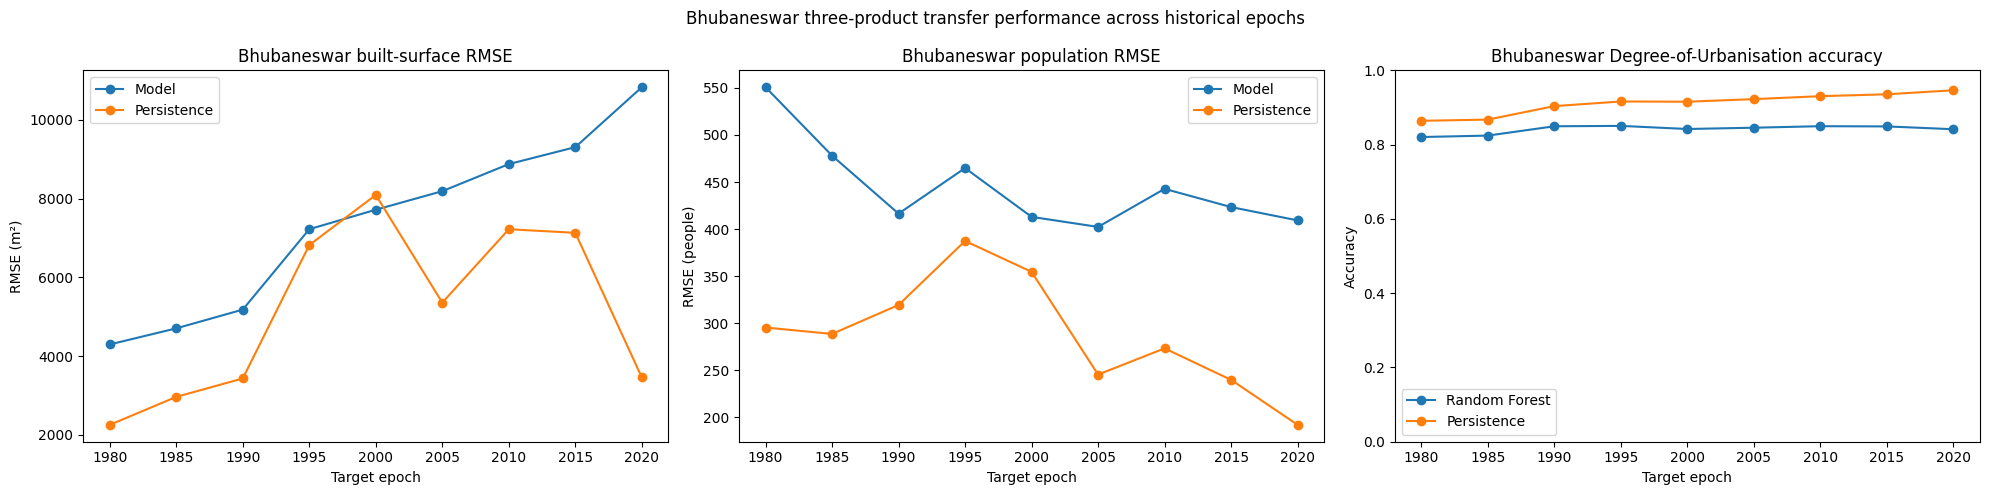

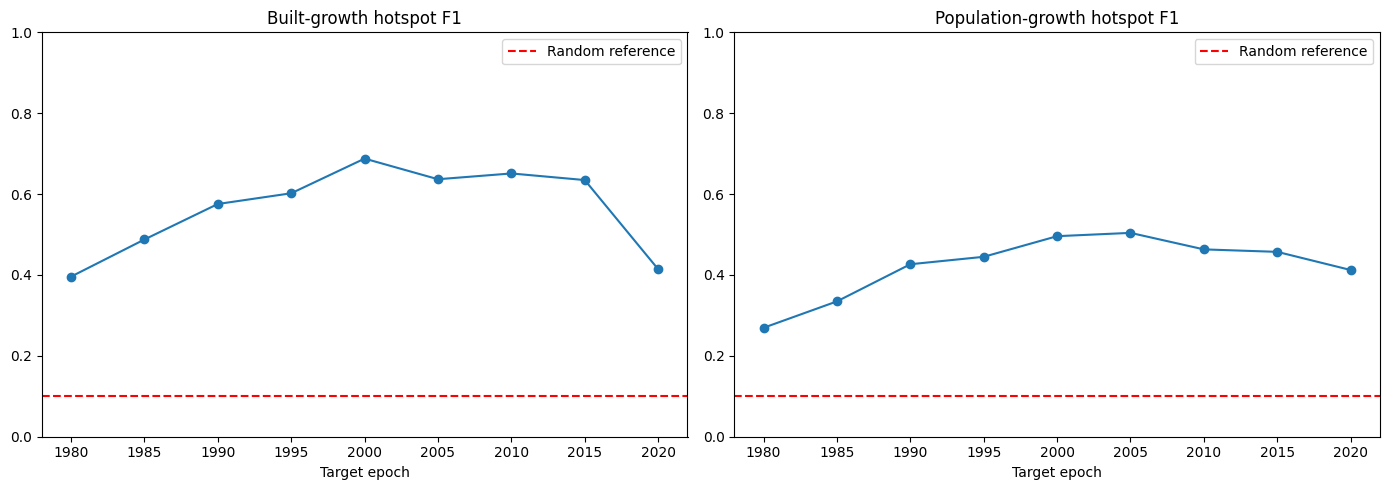

CELL 7: SUCCESS


In [44]:
# ============================================================
# CELL 7: ALL-EPOCH PERFORMANCE TREND FIGURES
# ============================================================
metric_data = pd.DataFrame([
    {
        'to_epoch': record['to_epoch'],
        'built_rmse': record['built_model']['rmse'],
        'built_persistence_rmse': record['built_persistence']['rmse'],
        'built_r2': record['built_model']['r2'],
        'built_hotspot_f1': record['built_hotspot_f1'],
        'population_rmse': record['population_model']['rmse'],
        'population_persistence_rmse': record['population_persistence']['rmse'],
        'population_r2': record['population_model']['r2'],
        'population_hotspot_f1': record['population_hotspot_f1'],
        'smod_accuracy': record['smod_accuracy'],
        'smod_persistence_accuracy': record['smod_persistence_accuracy'],
    }
    for record in RESULTS['metrics']
])

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
axes[0].plot(metric_data.to_epoch, metric_data.built_rmse, marker='o', label='Model')
axes[0].plot(metric_data.to_epoch, metric_data.built_persistence_rmse, marker='o', label='Persistence')
axes[0].set_title('Bhubaneswar built-surface RMSE')
axes[0].set_xlabel('Target epoch')
axes[0].set_ylabel('RMSE (m²)')
axes[0].legend()

axes[1].plot(metric_data.to_epoch, metric_data.population_rmse, marker='o', label='Model')
axes[1].plot(metric_data.to_epoch, metric_data.population_persistence_rmse, marker='o', label='Persistence')
axes[1].set_title('Bhubaneswar population RMSE')
axes[1].set_xlabel('Target epoch')
axes[1].set_ylabel('RMSE (people)')
axes[1].legend()

axes[2].plot(metric_data.to_epoch, metric_data.smod_accuracy, marker='o', label='Random Forest')
axes[2].plot(metric_data.to_epoch, metric_data.smod_persistence_accuracy, marker='o', label='Persistence')
axes[2].set_title('Bhubaneswar Degree-of-Urbanisation accuracy')
axes[2].set_xlabel('Target epoch')
axes[2].set_ylabel('Accuracy')
axes[2].set_ylim(0, 1)
axes[2].legend()

fig.suptitle('Bhubaneswar three-product transfer performance across historical epochs')
plt.tight_layout()
plt.savefig(FIGURE_ROOT / 'bhubaneswar_three_product_performance_by_epoch.png', dpi=200)
plt.show()
plt.close()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(metric_data.to_epoch, metric_data.built_hotspot_f1, marker='o')
axes[0].axhline(0.10, color='red', linestyle='--', label='Random reference')
axes[0].set_title('Built-growth hotspot F1')
axes[0].set_xlabel('Target epoch')
axes[0].set_ylim(0, 1)
axes[0].legend()
axes[1].plot(metric_data.to_epoch, metric_data.population_hotspot_f1, marker='o')
axes[1].axhline(0.10, color='red', linestyle='--', label='Random reference')
axes[1].set_title('Population-growth hotspot F1')
axes[1].set_xlabel('Target epoch')
axes[1].set_ylim(0, 1)
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURE_ROOT / 'bhubaneswar_growth_hotspot_f1_by_epoch.png', dpi=200)
plt.show()
plt.close()

print('CELL 7: SUCCESS')

In [45]:
# ============================================================
# CELL 8: ACTUAL-VS-PREDICTED SCATTERS, RESIDUALS, CONFUSION
# Produces one figure set for each of the nine target epochs.
# ============================================================
for target_epoch in TARGET_EPOCHS:
    source_epoch = target_epoch - 5
    data = pd.read_csv(
        ARTIFACT_ROOT / f'bhubaneswar_{source_epoch}_{target_epoch}_three_product_predictions.csv'
    )

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    specifications = [
        (
            'actual_next_built_surface_m2',
            'predicted_built_surface_m2',
            'Built surface',
            'm²',
        ),
        (
            'actual_next_population',
            'predicted_population',
            'Population',
            'people',
        ),
    ]
    for axis, (actual_column, predicted_column, title, unit) in zip(axes, specifications):
        actual = data[actual_column].astype(float)
        predicted = data[predicted_column].astype(float)
        minimum = min(actual.min(), predicted.min())
        maximum = max(actual.max(), predicted.max())
        axis.scatter(actual, predicted, s=7, alpha=0.28)
        axis.plot([minimum, maximum], [minimum, maximum], color='red', label='Perfect prediction')
        residual = predicted - actual
        rmse = np.sqrt(np.mean(residual ** 2))
        r2 = 1 - np.sum(residual ** 2) / np.sum((actual - actual.mean()) ** 2)
        axis.set_title(f'{title}: R²={r2:.4f}, RMSE={rmse:,.1f}')
        axis.set_xlabel(f'Actual {target_epoch} ({unit})')
        axis.set_ylabel(f'Predicted {target_epoch} ({unit})')
        axis.legend()
    fig.suptitle(f'Bhubaneswar {source_epoch}→{target_epoch}: actual vs predicted')
    plt.tight_layout()
    plt.savefig(
        FIGURE_ROOT / f'bhubaneswar_{source_epoch}_{target_epoch}_actual_vs_predicted.png',
        dpi=200,
    )
    plt.close()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].hist(data['built_error_m2'], bins=60)
    axes[0].axvline(0, color='red')
    axes[0].set_title('Built-surface errors')
    axes[0].set_xlabel('Predicted - actual (m²)')
    axes[1].hist(data['population_error'], bins=60)
    axes[1].axvline(0, color='red')
    axes[1].set_title('Population errors')
    axes[1].set_xlabel('Predicted - actual (people)')
    fig.suptitle(f'Bhubaneswar {source_epoch}→{target_epoch}: error distributions')
    plt.tight_layout()
    plt.savefig(
        FIGURE_ROOT / f'bhubaneswar_{source_epoch}_{target_epoch}_error_distributions.png',
        dpi=200,
    )
    plt.close()

    classes = sorted(
        set(data.actual_smod_class.astype(str))
        | set(data.predicted_smod_class.astype(str)),
        key=lambda value: int(float(value)),
    )
    confusion = pd.crosstab(
        data.actual_smod_class.astype(str),
        data.predicted_smod_class.astype(str),
    ).reindex(index=classes, columns=classes, fill_value=0)
    fig, axis = plt.subplots(figsize=(9, 7))
    image = axis.imshow(confusion.values, cmap='Blues')
    axis.set_xticks(range(len(classes)), classes, rotation=45)
    axis.set_yticks(range(len(classes)), classes)
    axis.set_xlabel('Predicted SMOD class')
    axis.set_ylabel('Actual SMOD class')
    axis.set_title(f'Bhubaneswar SMOD confusion matrix, {target_epoch}')
    fig.colorbar(image, ax=axis)
    plt.tight_layout()
    plt.savefig(FIGURE_ROOT / f'bhubaneswar_smod_confusion_{target_epoch}.png', dpi=200)
    plt.close()

print('Per-epoch scatter/residual/confusion figures created: 27')
print('CELL 8: SUCCESS')

Per-epoch scatter/residual/confusion figures created: 27
CELL 8: SUCCESS


In [46]:
# ============================================================
# CELL 9: SPATIAL THREE-PRODUCT MAPS FOR ALL NINE TARGET EPOCHS
# ============================================================
for target_epoch in TARGET_EPOCHS:
    source_epoch = target_epoch - 5
    data = pd.read_csv(
        ARTIFACT_ROOT / f'bhubaneswar_{source_epoch}_{target_epoch}_three_product_predictions.csv'
    )
    if len(data) != 4900:
        raise RuntimeError(f'{target_epoch}: expected 4,900 rows.')

    def pivot(column):
        return data.pivot(
            index='grid_1km_row',
            columns='grid_1km_col',
            values=column,
        ).sort_index(ascending=False)

    specifications = [
        (
            'Built surface',
            pivot('actual_next_built_surface_m2'),
            pivot('predicted_built_surface_m2'),
            'YlOrRd',
        ),
        (
            'Population',
            pivot('actual_next_population'),
            pivot('predicted_population'),
            'viridis',
        ),
        (
            'Degree of Urbanisation',
            pivot('actual_smod_class'),
            pivot('predicted_smod_class'),
            'tab20',
        ),
    ]

    figure, axes = plt.subplots(3, 3, figsize=(18, 16))
    for row_index, (name, actual_map, predicted_map, color_map) in enumerate(specifications):
        actual_map = actual_map.astype(float)
        predicted_map = predicted_map.astype(float)
        error_map = predicted_map - actual_map

        if name == 'Degree of Urbanisation':
            minimum = min(np.nanmin(actual_map), np.nanmin(predicted_map))
            maximum = max(np.nanmax(actual_map), np.nanmax(predicted_map))
        else:
            pooled = np.concatenate([
                actual_map.values.ravel(),
                predicted_map.values.ravel(),
            ])
            minimum = np.nanpercentile(pooled, 1)
            maximum = np.nanpercentile(pooled, 99)

        image = axes[row_index, 0].imshow(
            actual_map, cmap=color_map, vmin=minimum, vmax=maximum
        )
        axes[row_index, 0].set_title(f'Actual {name}')
        figure.colorbar(image, ax=axes[row_index, 0], fraction=0.046)

        image = axes[row_index, 1].imshow(
            predicted_map, cmap=color_map, vmin=minimum, vmax=maximum
        )
        axes[row_index, 1].set_title(f'Predicted {name}')
        figure.colorbar(image, ax=axes[row_index, 1], fraction=0.046)

        error_limit = max(
            abs(np.nanpercentile(error_map.values, 1)),
            abs(np.nanpercentile(error_map.values, 99)),
            1,
        )
        image = axes[row_index, 2].imshow(
            error_map, cmap='coolwarm', vmin=-error_limit, vmax=error_limit
        )
        axes[row_index, 2].set_title(f'{name} error')
        figure.colorbar(image, ax=axes[row_index, 2], fraction=0.046)

        for axis in axes[row_index]:
            axis.set_axis_off()

    figure.suptitle(
        f'Bhubaneswar {source_epoch}→{target_epoch}: actual vs predicted three-product comparison',
        fontsize=16,
    )
    plt.tight_layout()
    output_path = SPATIAL_ROOT / f'bhubaneswar_{source_epoch}_{target_epoch}_three_product_spatial.png'
    plt.savefig(output_path, dpi=180, bbox_inches='tight')
    plt.close()

print('Three-product spatial figures created:', len(list(SPATIAL_ROOT.glob('*three_product_spatial.png'))))
print('CELL 9: SUCCESS')

Three-product spatial figures created: 9
CELL 9: SUCCESS


In [47]:
# ============================================================
# CELL 10: BUILT AND POPULATION GROWTH-HOTSPOT MAPS
# ============================================================
for target_epoch in TARGET_EPOCHS:
    source_epoch = target_epoch - 5
    data = pd.read_csv(
        ARTIFACT_ROOT / f'bhubaneswar_{source_epoch}_{target_epoch}_three_product_predictions.csv'
    )
    hotspot_count = 490

    for prefix, actual_column, predicted_column, title in [
        (
            'built',
            'actual_built_growth_m2',
            'predicted_built_growth_m2',
            'Built-surface growth',
        ),
        (
            'population',
            'actual_population_change',
            'predicted_population_change',
            'Population growth',
        ),
    ]:
        actual_indices = set(
            data.nlargest(hotspot_count, actual_column).index
        )
        predicted_indices = set(
            data.nlargest(hotspot_count, predicted_column).index
        )
        correct_indices = actual_indices & predicted_indices

        data['actual_hotspot'] = data.index.isin(actual_indices)
        data['predicted_hotspot'] = data.index.isin(predicted_indices)
        data['correct_hotspot'] = data.index.isin(correct_indices)

        def pivot(column):
            return data.pivot(
                index='grid_1km_row',
                columns='grid_1km_col',
                values=column,
            ).sort_index(ascending=False)

        figure, axes = plt.subplots(1, 3, figsize=(16, 5))
        maps = [
            ('Actual top 10%', pivot('actual_hotspot'), 'Reds'),
            ('Predicted top 10%', pivot('predicted_hotspot'), 'Blues'),
            ('Correct overlap', pivot('correct_hotspot'), 'Greens'),
        ]
        for axis, (map_title, map_data, color_map) in zip(axes, maps):
            axis.imshow(map_data, cmap=color_map, vmin=0, vmax=1)
            axis.set_title(map_title)
            axis.set_axis_off()

        hotspot_f1 = len(correct_indices) / float(hotspot_count)
        figure.suptitle(
            f'Bhubaneswar {source_epoch}→{target_epoch} {title} hotspots, F1={hotspot_f1:.2%}'
        )
        plt.tight_layout()
        plt.savefig(
            SPATIAL_ROOT / f'bhubaneswar_{source_epoch}_{target_epoch}_{prefix}_hotspots.png',
            dpi=180,
            bbox_inches='tight',
        )
        plt.close()

print('Hotspot figures created:', len(list(SPATIAL_ROOT.glob('*hotspots.png'))))
print('CELL 10: SUCCESS')

Hotspot figures created: 18
CELL 10: SUCCESS


In [48]:
# ============================================================
# CELL 11: SAVE FINAL MANIFEST AND COMPLETION GATE
# ============================================================
primary_result = next(
    record for record in RESULTS['metrics'] if record['to_epoch'] == 2020
)

manifest = {
    'created_at_utc': time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()),
    'city': 'Bhubaneswar Metropolitan Region',
    'city_slug': 'bhubaneswar',
    'bhubaneswar_used_in_training': False,
    'actual_epochs': ACTUAL_EPOCHS,
    'prediction_target_epochs': TARGET_EPOCHS,
    'baseline_epoch_without_prediction': 1975,
    'prediction_comparisons': 9,
    'rows_per_comparison': 4900,
    'total_prediction_rows': 44100,
    'models': {
        'built_surface': {
            'type': 'Linear Regression',
            'path': BUILT_MODEL,
            'target': 'built_surface_total_m2',
        },
        'population': {
            'type': 'Linear Regression',
            'path': POPULATION_MODEL,
            'target': 'population_total',
        },
        'degree_of_urbanisation': {
            'type': 'Random Forest Classifier',
            'path': SMOD_MODEL,
            'target': 'smod_class',
        },
    },
    'primary_unseen_city_unseen_time_test': '2015->2020',
    'primary_2015_2020_metrics': primary_result,
    'hdfs_outputs': {
        'transitions': BHUBANESWAR_THREE_TARGET_TRANSITIONS,
        'cell_predictions': CELL_PREDICTIONS,
        'summary_tables': SUMMARY_TABLES,
    },
    'drive_output': str(ARTIFACT_ROOT),
    'figures': len(list(FIGURE_ROOT.rglob('*.png'))),
    'source_datasets_modified': False,
}

manifest_path = ARTIFACT_ROOT / 'bhubaneswar_three_product_evaluation_manifest.json'
manifest_path.write_text(
    json.dumps(manifest, indent=2, sort_keys=True) + '\n',
    encoding='utf-8',
)

print('Bhubaneswar actual epochs available: 10/10')
print('Five-year prediction comparisons: 9/9')
print('1975 retained as observed baseline: YES')
print('Built-surface predictions evaluated: COMPLETE')
print('Population predictions evaluated: COMPLETE')
print('Degree-of-Urbanisation predictions evaluated: COMPLETE')
print('Persistence comparisons: COMPLETE')
print('All-epoch metrics and CSV exports: COMPLETE')
print('All-epoch actual-vs-predicted figures: COMPLETE')
print('All-epoch spatial figures: COMPLETE')
print('All-epoch growth-hotspot figures: COMPLETE')
print('Primary 2015->2020 transfer test: COMPLETE')
print('Bhubaneswar used in training: NO')
print('Source HDFS datasets modified: NO')
print('NOTEBOOK_18_BHUBANESWAR_THREE_PRODUCT_EVALUATION_SUCCESS')
print('CELL 11: SUCCESS')

Bhubaneswar actual epochs available: 10/10
Five-year prediction comparisons: 9/9
1975 retained as observed baseline: YES
Built-surface predictions evaluated: COMPLETE
Population predictions evaluated: COMPLETE
Degree-of-Urbanisation predictions evaluated: COMPLETE
Persistence comparisons: COMPLETE
All-epoch metrics and CSV exports: COMPLETE
All-epoch actual-vs-predicted figures: COMPLETE
All-epoch spatial figures: COMPLETE
All-epoch growth-hotspot figures: COMPLETE
Primary 2015->2020 transfer test: COMPLETE
Bhubaneswar used in training: NO
Source HDFS datasets modified: NO
NOTEBOOK_18_BHUBANESWAR_THREE_PRODUCT_EVALUATION_SUCCESS
CELL 11: SUCCESS


In [49]:
# ============================================================
# FINAL DISPLAY: CONSISTENT ACTUAL / PREDICTED / ERROR MAPS
# Displays and saves one 3 x 3 figure for each of nine transitions.
# ============================================================
from matplotlib.colors import ListedColormap,BoundaryNorm
from matplotlib.patches import Patch
SMOD_ORDER=[0,10,11,12,13,21,22,23,30]
SMOD_LABELS={0:'No data',10:'Water',11:'Very low-density rural',12:'Low-density rural',13:'Rural cluster',21:'Suburban / peri-urban',22:'Semi-dense urban cluster',23:'Dense urban cluster',30:'Urban centre'}
SMOD_COLORS=['#d9d9d9','#4f9bd9','#ffffcc','#c7e9b4','#41ab5d','#fdae61','#f46d43','#d73027','#7f0000']
SMOD_MAP={v:i for i,v in enumerate(SMOD_ORDER)};SMOD_CMAP=ListedColormap(SMOD_COLORS);SMOD_NORM=BoundaryNorm(np.arange(-.5,len(SMOD_ORDER)+.5,1),SMOD_CMAP.N);AGREE=ListedColormap(['#d73027','#1a9850'])
def grid(d,c):
 g=d.pivot(index='grid_1km_row',columns='grid_1km_col',values=c).sort_index(ascending=False)
 if g.shape!=(70,70):raise RuntimeError(f'{c}: expected 70 x 70, found {g.shape}')
 return g
def reg(a,p):
 a=np.asarray(a,float);p=np.asarray(p,float);m=np.isfinite(a)&np.isfinite(p);a=a[m];p=p[m];e=p-a;den=np.sum((a-a.mean())**2)
 return {'mae':np.mean(abs(e)),'rmse':np.sqrt(np.mean(e**2)),'r2':np.nan if den==0 else 1-np.sum(e**2)/den,'bias':np.mean(e)}
def rng(a,p):
 z=np.concatenate([a.values.ravel(),p.values.ravel()]);z=z[np.isfinite(z)];return 0,max(float(np.nanpercentile(z,99.5)),1)
def elim(e):
 z=np.abs(e.values.ravel());z=z[np.isfinite(z)];return max(float(np.nanpercentile(z,99)),1)
outdir=ARTIFACT_ROOT/'figures'/'consistent_spatial';outdir.mkdir(parents=True,exist_ok=True);inventory=[]
for target in TARGET_EPOCHS:
 source=target-5;path=ARTIFACT_ROOT/f'bhubaneswar_{source}_{target}_three_product_predictions.csv';d=pd.read_csv(path)
 if len(d)!=4900:raise RuntimeError(f'{path}: expected 4900 rows')
 bm=reg(d.actual_next_built_surface_m2,d.predicted_built_surface_m2);pm=reg(d.actual_next_population,d.predicted_population)
 ba,bp=grid(d,'actual_next_built_surface_m2'),grid(d,'predicted_built_surface_m2');pa,pp=grid(d,'actual_next_population'),grid(d,'predicted_population');sa_raw,sp_raw=grid(d,'actual_smod_class'),grid(d,'predicted_smod_class');sa=sa_raw.replace(SMOD_MAP).astype(float);sp=sp_raw.replace(SMOD_MAP).astype(float);agree=(sa_raw==sp_raw).astype(int);sacc=float(agree.values.mean());pacc=float((d.smod_class.astype(str)==d.actual_smod_class.astype(str)).mean())
 fig,ax=plt.subplots(3,3,figsize=(20,17));bmin,bmax=rng(ba,bp);pmin,pmax=rng(pa,pp);be=bp-ba;pe=pp-pa
 specs=[(ba,bp,be,'Built surface','YlOrRd',bmin,bmax,elim(be),'m²',bm),(pa,pp,pe,'Population','viridis',pmin,pmax,elim(pe),'people',pm)]
 for r,(a,p,e,name,cmap,vmin,vmax,limit,unit,m) in enumerate(specs):
  im=ax[r,0].imshow(a,cmap=cmap,vmin=vmin,vmax=vmax);ax[r,0].set_title(f'Actual {name} {target}');fig.colorbar(im,ax=ax[r,0],fraction=.046,label=unit)
  im=ax[r,1].imshow(p,cmap=cmap,vmin=vmin,vmax=vmax);ax[r,1].set_title(f'Predicted {name} {target}');fig.colorbar(im,ax=ax[r,1],fraction=.046,label=unit)
  im=ax[r,2].imshow(e,cmap='coolwarm',vmin=-limit,vmax=limit);ax[r,2].set_title(f'{name} error\npredicted - actual');fig.colorbar(im,ax=ax[r,2],fraction=.046,label=f'Error ({unit})')
  ax[r,1].text(.5,-.08,f'MAE={m["mae"]:,.1f} | RMSE={m["rmse"]:,.1f} | R²={m["r2"]:.4f} | Bias={m["bias"]:+,.1f}',transform=ax[r,1].transAxes,ha='center',va='top',fontsize=10,bbox={'boxstyle':'round,pad=.3','facecolor':'white','alpha':.85})
 ax[2,0].imshow(sa,cmap=SMOD_CMAP,norm=SMOD_NORM);ax[2,0].set_title(f'Actual Degree of Urbanisation {target}');ax[2,1].imshow(sp,cmap=SMOD_CMAP,norm=SMOD_NORM);ax[2,1].set_title(f'Predicted Degree of Urbanisation {target}');ax[2,2].imshow(agree,cmap=AGREE,vmin=0,vmax=1);ax[2,2].set_title('SMOD agreement\nred = incorrect, green = correct');ax[2,1].text(.5,-.08,f'Random Forest accuracy={sacc:.2%} | Persistence={pacc:.2%} | Difference={sacc-pacc:+.2%}',transform=ax[2,1].transAxes,ha='center',va='top',fontsize=10,bbox={'boxstyle':'round,pad=.3','facecolor':'white','alpha':.85})
 for row in ax:
  for a in row:a.set_axis_off()
 fig.legend(handles=[Patch(facecolor=SMOD_COLORS[i],label=f'{v}: {SMOD_LABELS[v]}') for i,v in enumerate(SMOD_ORDER)],loc='lower center',ncol=3,fontsize=9,bbox_to_anchor=(.42,.004),title='Degree-of-Urbanisation classes');fig.legend(handles=[Patch(facecolor='#1a9850',label='Correct'),Patch(facecolor='#d73027',label='Incorrect')],loc='lower center',ncol=2,fontsize=9,bbox_to_anchor=(.82,.025),title='Classification')
 fig.suptitle(f'Bhubaneswar {source}→{target}: actual versus predicted GHSL products',fontsize=18,y=.995);plt.tight_layout(rect=[0,.105,1,.97]);out=outdir/f'bhubaneswar_{source}_{target}_consistent_three_product_comparison.png';plt.savefig(out,dpi=200,bbox_inches='tight');plt.show();plt.close(fig);inventory.append({'from_epoch':source,'to_epoch':target,'path':str(out),'built_metrics':bm,'population_metrics':pm,'smod_accuracy':sacc,'smod_persistence_accuracy':pacc})
(ARTIFACT_ROOT/'consistent_spatial_figure_inventory.json').write_text(json.dumps(inventory,indent=2,sort_keys=True)+'\n')
print('Consistent Bhubaneswar figures:',len(inventory));print('BHUBANESWAR CONSISTENT THREE-PRODUCT FIGURES: SUCCESS')

Output hidden; open in https://colab.research.google.com to view.